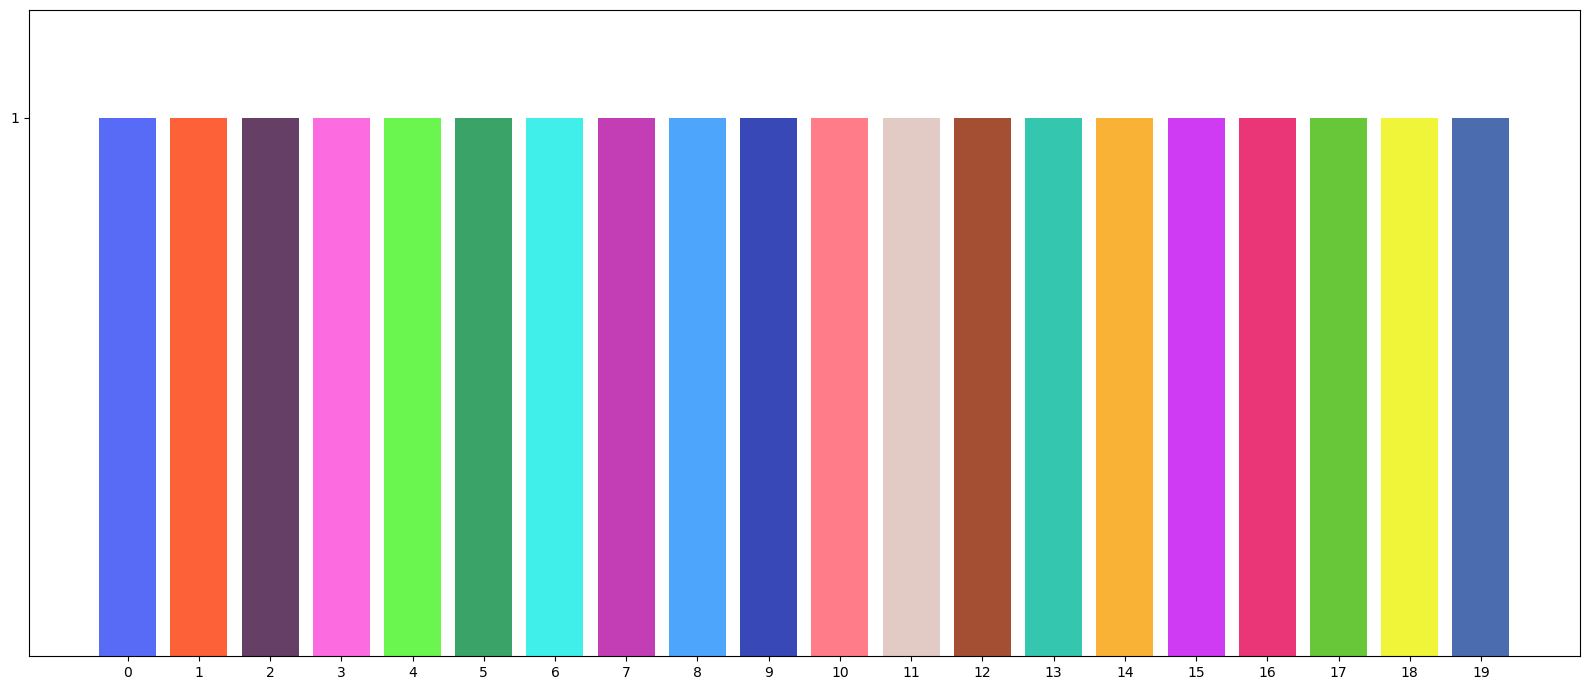

In [1]:
import glob, re, joblib
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
import string
import matplotlib.patches as mpatches
from Utils import colors_to_use
N = len(colors_to_use)

plt.figure(figsize=(16, 7))

plt.bar(
    range(N),
    [1] * N,
    color=colors_to_use
)

plt.xticks(range(N))
plt.yticks([1])
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

# Fig 1

## k-NN

In [2]:
files = sorted(glob.glob(
    "Datasets/*/XplainTDA/*/Stability/kNN/bottleneck_pairwise_long.csv"
))


def parse_path(f):
    """Extract dataset and omic from Datasets/<dataset>/XplainTDA/<omic>/..."""
    parts = Path(f).parts
    i = parts.index("Datasets")
    return parts[i + 1], parts[i + 3]


def k_value(label):
    """Convert labels like 'k=50' to 50; use infinity for the full graph."""
    if label == "full":
        return np.inf
    m = re.search(r"k=(\d+)", str(label))
    return int(m.group(1)) if m else np.nan


def finite_persistences(dgms, dim):
    """Finite lifetimes death-birth for one homology dimension."""
    dgm = np.asarray(dgms[int(dim)], dtype=float)
    if dgm.size == 0:
        return np.array([], dtype=float)

    dgm = dgm[np.isfinite(dgm).all(axis=1)]
    pers = dgm[:, 1] - dgm[:, 0]
    return pers[pers > 0]


def load_tda_states(outdir):
    """
    Load saved PH objects.

    Each state contains at least dgms and edge_list.
    Your kNN script saves tda_full_distance.joblib and tda_knn_k*.joblib.
    """
    tda_dir = outdir / "tda_objects"
    states = {}

    full_path = tda_dir / "tda_full_distance.joblib"
    if full_path.exists():
        states["full"] = joblib.load(full_path)

    for path in sorted(tda_dir.glob("tda_knn_k*.joblib")):
        m = re.search(r"tda_knn_k(\d+)\.joblib$", path.name)
        if m:
            states[f"k={int(m.group(1))}"] = joblib.load(path)

    return states


def filtration_range(state):
    """
    Effective filtration range of one saved object.

    Vertices are born at 0, so the range is max edge filtration - 0.
    If edge_list is unavailable, fall back to the largest finite death time.
    """
    edge_list = state.get("edge_list", None)

    if edge_list is not None and np.asarray(edge_list).size:
        return float(np.nanmax(np.asarray(edge_list)[:, 2]))

    deaths = [
        np.asarray(dgm)[:, 1]
        for dgm in state["dgms"]
        if np.asarray(dgm).size
    ]

    deaths = np.concatenate(deaths) if deaths else np.array([])
    deaths = deaths[np.isfinite(deaths)]

    return float(np.nanmax(deaths)) if deaths.size else np.nan


def safe_divide(x, s):
    """Avoid division by zero or missing denominators."""
    return x / s if np.isfinite(s) and s > 0 else np.nan


def add_normalisations(tmp, f):
    outdir = Path(f).parent
    states = load_tda_states(outdir)

    # 1) Diameter of the embedded space:
    #    max pairwise distance between cells in the full embedding.
    D_path = outdir / "full_distance_matrix.npy"
    if not D_path.exists():
        raise FileNotFoundError(f"Missing {D_path}")

    D = np.load(D_path)
    Dpos = D[np.isfinite(D) & (D > 0)]
    S_diameter = float(np.nanmax(Dpos))

    # 2) Filtration range:
    #    row-specific scale based on the two compared PH objects.
    #    For k-vs-k comparisons this uses the kNN filtration ranges;
    #    for full-vs-k comparisons this usually equals the full graph scale.
    S_filt_by_label = {
        label: filtration_range(state)
        for label, state in states.items()
    }

    # 3) Longest-lived feature scale, per homology dimension:
    #    max persistence across all saved diagrams in that dimension.
    S_life_by_dim = {}

    for dim in sorted(tmp["homology_dim"].unique()):
        pers = [
            finite_persistences(state["dgms"], dim)
            for state in states.values()
            if int(dim) < len(state["dgms"])
        ]
        pers = [p for p in pers if p.size]

        S_life_by_dim[int(dim)] = (
            float(np.nanmax(np.concatenate(pers)))
            if pers else np.nan
        )

    tmp = tmp.copy()

    tmp["S_diameter"] = S_diameter

    tmp["S_filtration_range"] = [
        np.nanmax([
            S_filt_by_label.get(row.label_a, np.nan),
            S_filt_by_label.get(row.label_b, np.nan),
        ])
        for row in tmp.itertuples(index=False)
    ]

    tmp["S_longest_lifespan_dim"] = [
        S_life_by_dim[int(dim)]
        for dim in tmp["homology_dim"]
    ]

    tmp["bottleneck_norm_by_diameter"] = [
        safe_divide(row.bottleneck_distance, row.S_diameter)
        for row in tmp.itertuples(index=False)
    ]

    tmp["bottleneck_norm_by_filtration_range"] = [
        safe_divide(row.bottleneck_distance, row.S_filtration_range)
        for row in tmp.itertuples(index=False)
    ]

    tmp["bottleneck_norm_by_longest_lifespan_dim"] = [
        safe_divide(row.bottleneck_distance, row.S_longest_lifespan_dim)
        for row in tmp.itertuples(index=False)
    ]

    return tmp


dfs = []

for f in files:
    dataset, omic = parse_path(f)
    tmp = pd.read_csv(f)

    tmp["dataset"] = dataset
    tmp["omic"] = omic
    tmp["source_file"] = f

    tmp["k_a"] = tmp["label_a"].map(k_value)
    tmp["k_b"] = tmp["label_b"].map(k_value)

    tmp = add_normalisations(tmp, f)
    dfs.append(tmp)

if not dfs:
    raise FileNotFoundError(
        "No Run_Stability_kNN outputs found under "
        "Datasets/*/XplainTDA/*/Stability/kNN/"
    )

df = pd.concat(dfs, ignore_index=True)

df0 = df[df["homology_dim"] == 0].copy()
df1 = df[df["homology_dim"] == 1].copy()
df2 = df[df["homology_dim"] == 2].copy()

df

,label_a,label_b,homology_dim,bottleneck_distance,dataset,omic,source_file,k_a,k_b,S_diameter,S_filtration_range,S_longest_lifespan_dim,bottleneck_norm_by_diameter,bottleneck_norm_by_filtration_range,bottleneck_norm_by_longest_lifespan_dim
0,full,k=5,0,9.199380e-01,HumanBrain,GEX,Datasets/HumanBrain/XplainTDA/GEX/Stability/kN...,inf,5,1.839876,1.839876,1.839876,5.000000e-01,5.000000e-01,5.000000e-01
1,full,k=15,0,9.199380e-01,HumanBrain,GEX,Datasets/HumanBrain/XplainTDA/GEX/Stability/kN...,inf,15,1.839876,1.839876,1.839876,5.000000e-01,5.000000e-01,5.000000e-01
2,full,k=50,0,9.199380e-01,HumanBrain,GEX,Datasets/HumanBrain/XplainTDA/GEX/Stability/kN...,inf,50,1.839876,1.839876,1.839876,5.000000e-01,5.000000e-01,5.000000e-01
3,full,k=75,0,9.083050e-01,HumanBrain,GEX,Datasets/HumanBrain/XplainTDA/GEX/Stability/kN...,inf,75,1.839876,1.839876,1.839876,4.936773e-01,4.936773e-01,4.936773e-01
4,full,k=100,0,8.699671e-01,HumanBrain,GEX,Datasets/HumanBrain/XplainTDA/GEX/Stability/kN...,inf,100,1.839876,1.839876,1.839876,4.728401e-01,4.728401e-01,4.728401e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
865,k=750,k=1250,1,8.520968e-03,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/kNN/bot...,750.0,1250,2.280705,1.076367,0.630741,3.736111e-03,7.916413e-03,1.350946e-02
866,k=750,k=1250,2,7.438660e-05,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/kNN/bot...,750.0,1250,2.280705,1.076367,0.746730,3.261561e-05,6.910893e-05,9.961644e-05
867,k=1000,k=1250,0,2.332783e-02,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/kNN/bot...,1000.0,1250,2.280705,1.076367,2.280705,1.022834e-02,2.167274e-02,1.022834e-02
868,k=1000,k=1250,1,8.520968e-03,PBMC,Peak,Datasets/PBMC/XplainTDA/Peak/Stability/kNN/bot...,1000.0,1250,2.280705,1.076367,0.630741,3.736111e-03,7.916413e-03,1.350946e-02


In [3]:
[col for col in df.columns if "bottleneck" in col]

['bottleneck_distance',
 'bottleneck_norm_by_diameter',
 'bottleneck_norm_by_filtration_range',
 'bottleneck_norm_by_longest_lifespan_dim']

In [ ]:
datasets, omics, dims = ["PBMC", "HumanBrain", "MouseBrain"], ["GEX", "Peak"], [0, 1, 2]

for dataset in datasets[:1]:
    fig, axes = plt.subplots(len(omics), len(dims), figsize=(30, 12), dpi=300)

    for i, omic in enumerate(omics):
        for j, dim in enumerate(dims):
            ax = axes[i, j]
            sub = df[(df["dataset"] == dataset) & (df["omic"] == omic) & (df["homology_dim"] == dim)]

            if sub.empty:
                ax.axis("off")
                ax.set_title(f"H{dim} — missing")
                continue

            labels = sorted(set(sub["label_a"]) | set(sub["label_b"]),
                            key=lambda x: -1 if x == "full" else k_value(x))
            if dim > 0:
                labels = [x for x in labels if x != "full"]

            mat = pd.DataFrame(0.0, index=labels, columns=labels)
            for r in sub.itertuples(index=False):
                if r.label_a in labels and r.label_b in labels:
                    mat.loc[r.label_a, r.label_b] = mat.loc[r.label_b, r.label_a] = r.bottleneck_distance

            vals = mat.to_numpy()
            off = vals[~np.eye(vals.shape[0], dtype=bool)]
            off = off[np.isfinite(off)]
            vmin, vmax = (off.min(), off.max()) if len(off) else (vals.min(), vals.max())

            sns.heatmap(mat, ax=ax, cmap="viridis", vmin=vmin, vmax=vmax,
                        annot=True, fmt=".2g", square=True, linewidths=0.4,
                        linecolor="white", cbar=True,
                        cbar_kws={"label": f"Bottleneck distance, H{dim}", "shrink": 0.75})

            ax.set_title(f"H{dim}" if i == 0 else "", fontsize=13)
            ax.set_ylabel(("ATAC" if omic == "Peak" else omic) if j == 0 else "", fontsize=12)
            ax.set_xlabel("")
            ax.tick_params(axis="x", rotation=90)
            ax.tick_params(axis="y", rotation=0)

    fig.suptitle(f"{dataset} kNN stability bottleneck heatmaps", fontsize=16)
    plt.tight_layout()
    plt.show()

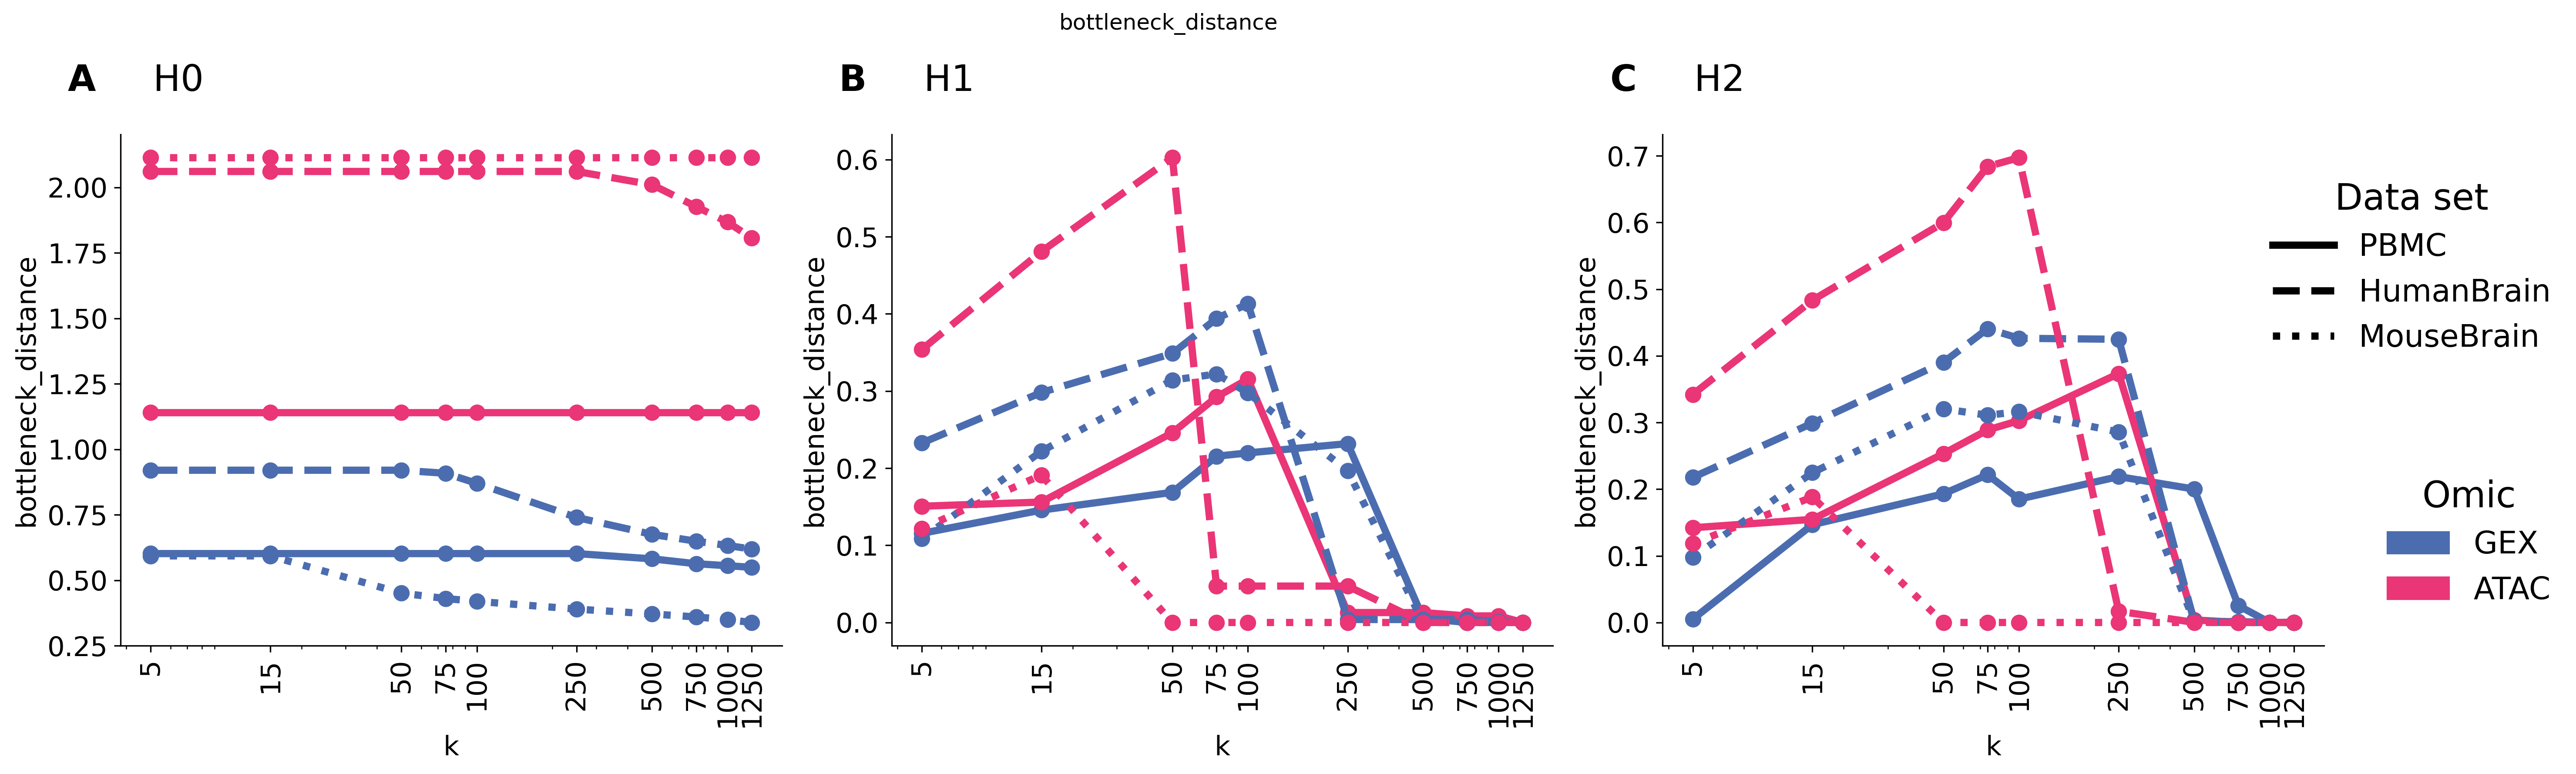

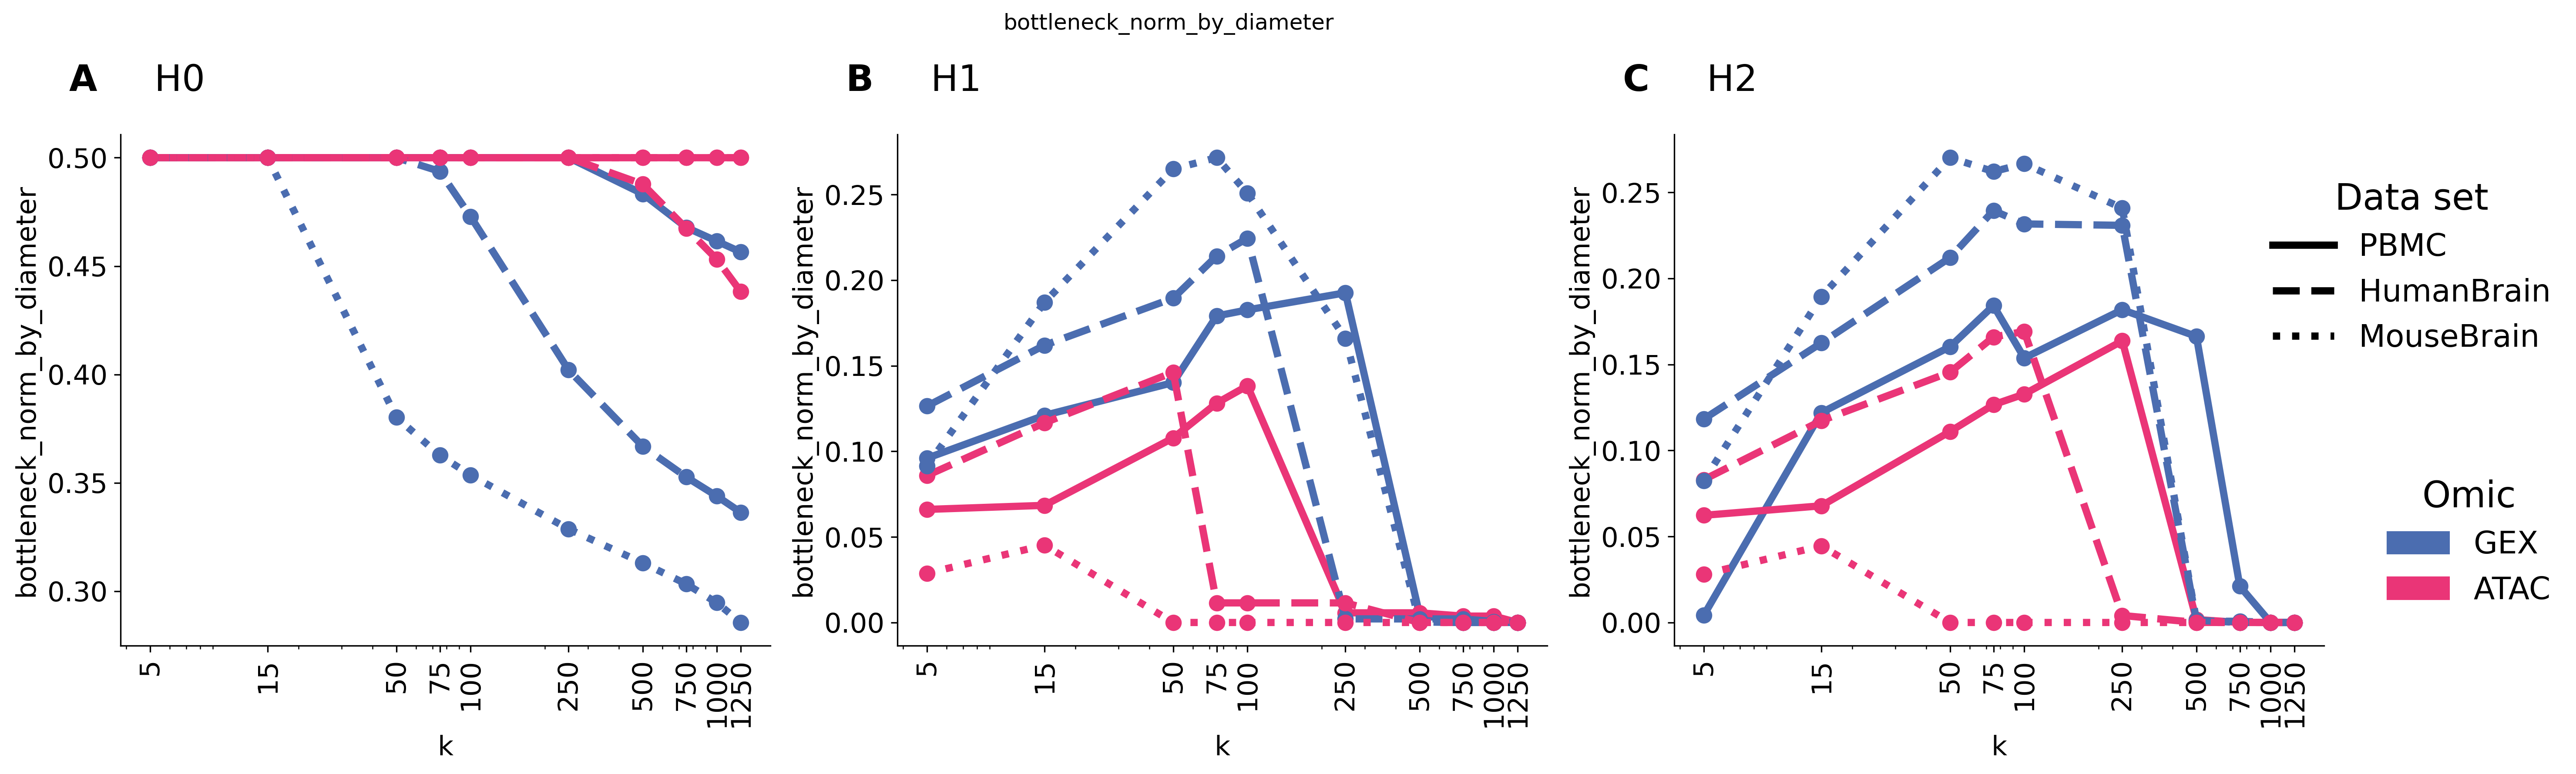

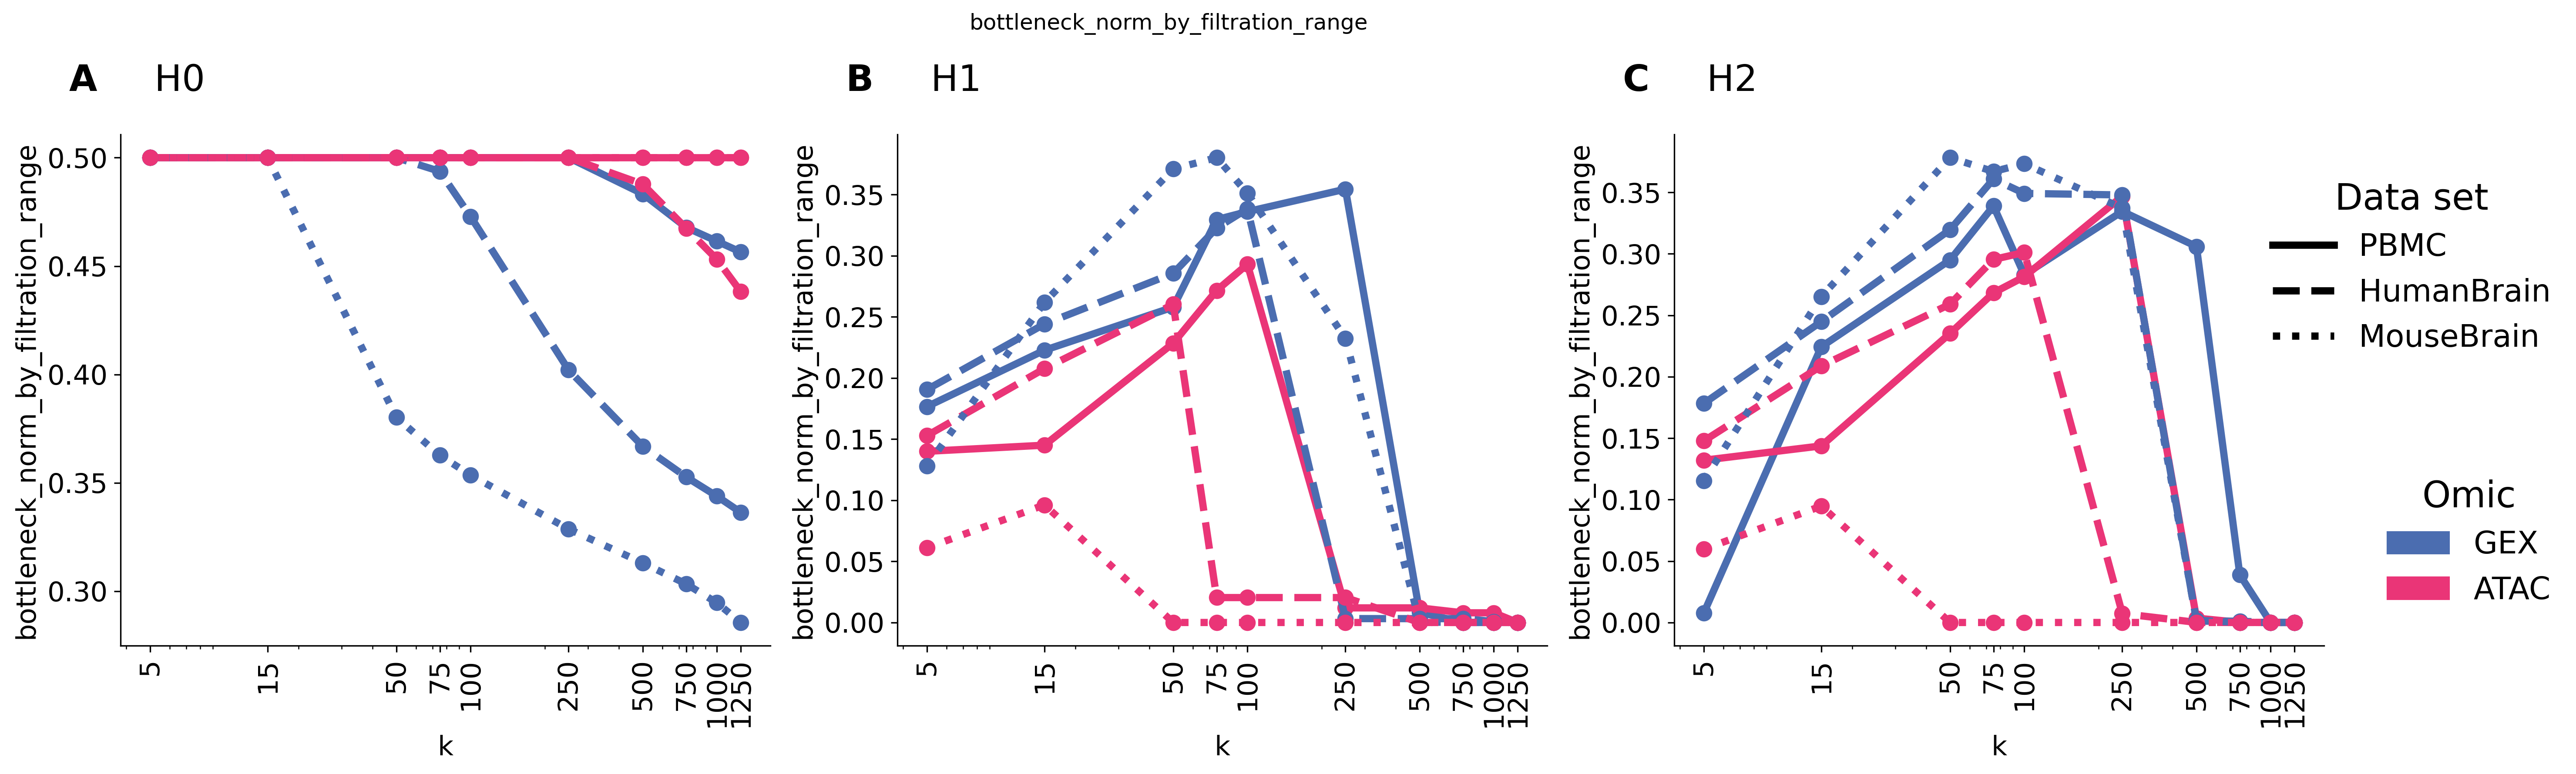

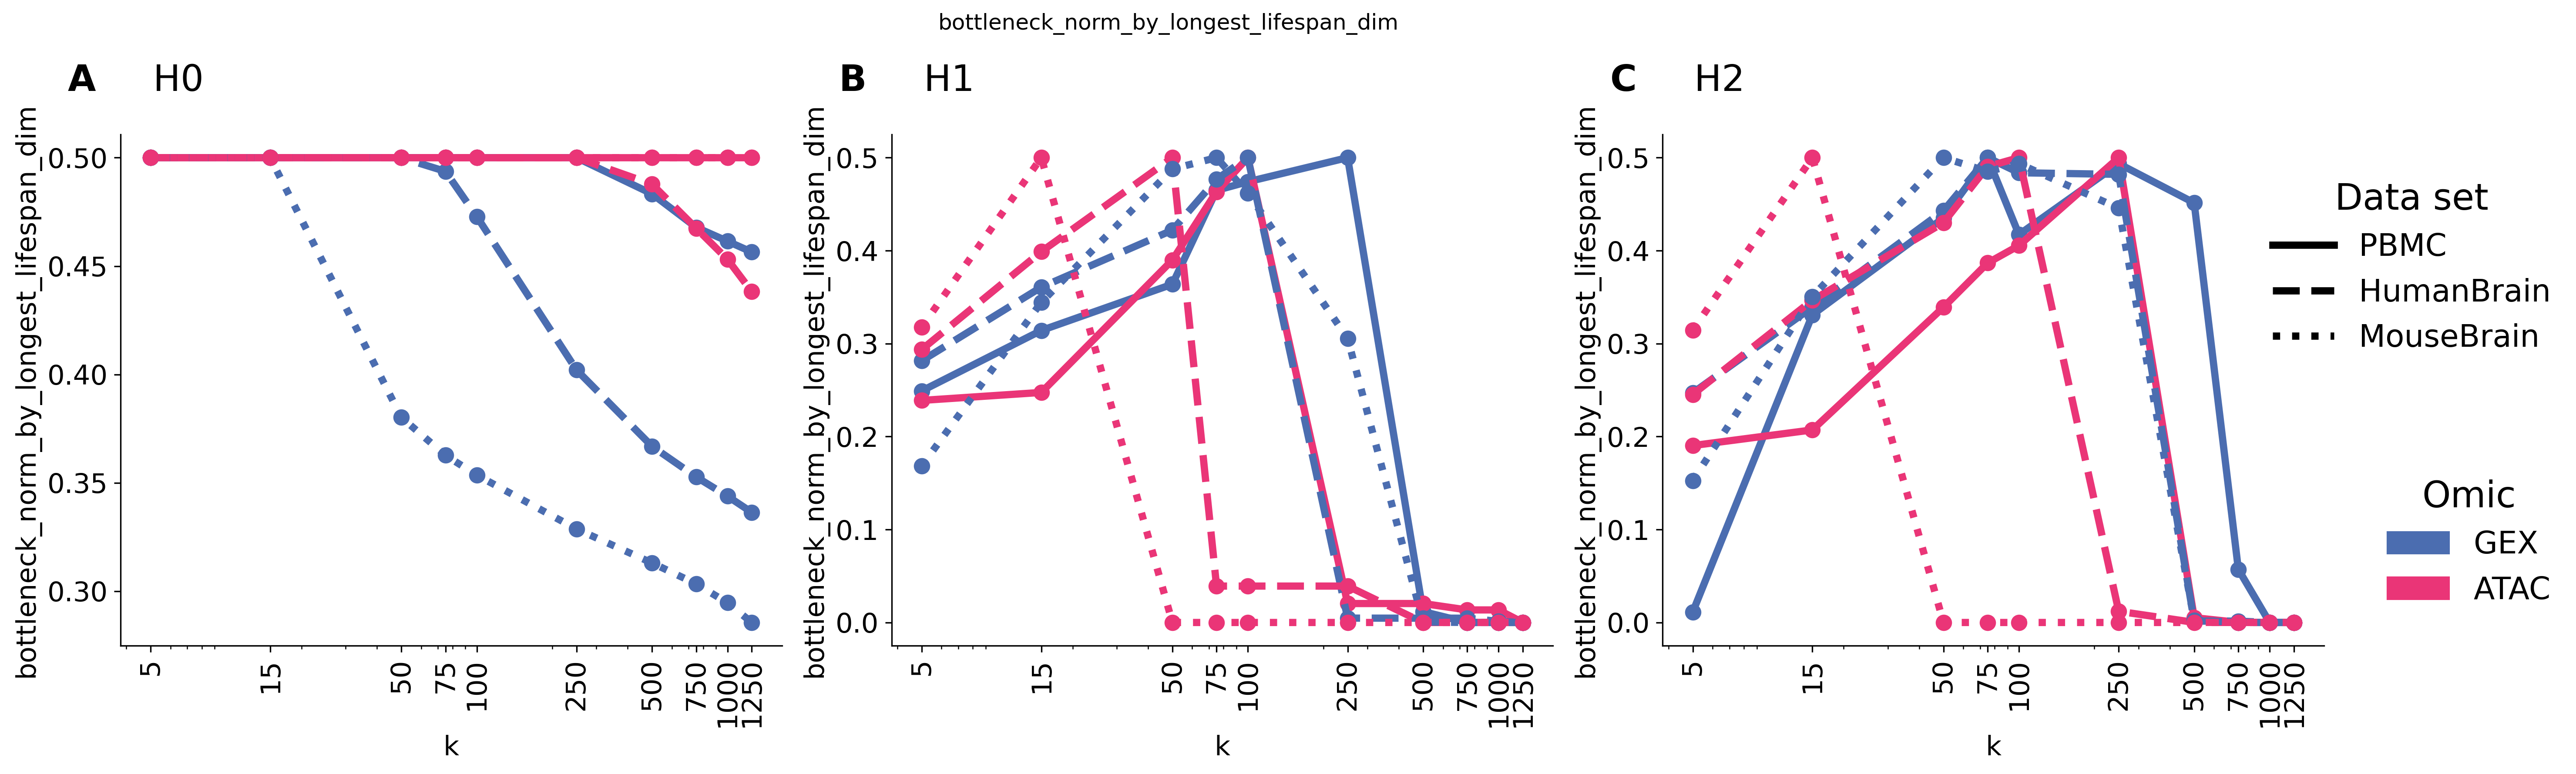

In [5]:
datasets = ["PBMC", "HumanBrain", "MouseBrain"]
omics, dims = ["GEX", "Peak"], [0, 1, 2]
omic_colors = {"GEX": colors_to_use[19], "Peak": colors_to_use[16]}
omic_labels = {"GEX": "GEX", "Peak": "ATAC"}
dataset_styles = {"PBMC": "-", "HumanBrain": "--", "MouseBrain": ":"}

plt.rcParams.update({
    "axes.labelsize": 15, "axes.titlesize": 15,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "lines.linewidth": 4, "figure.dpi": 300,
    "figure.figsize": [18, 6],
})


def get_h0_to_full(sub):
    mask = ((sub["label_a"] == "full") & sub["label_b"].str.startswith("k=")) | \
           ((sub["label_b"] == "full") & sub["label_a"].str.startswith("k="))
    out = sub[mask].copy()
    if out.empty: return out

    out["k"] = np.where(out["label_a"] == "full", out["label_b"].map(k_value), out["label_a"].map(k_value))
    out["reference"] = "full"
    return out.sort_values("k")


def get_hi_to_largest_k(sub, distance):
    labels = sorted(set(sub["label_a"]).union(sub["label_b"]), key=k_value)
    labels = [x for x in labels if str(x).startswith("k=")]
    if not labels: return pd.DataFrame()

    ref_label, ref_k = labels[-1], k_value(labels[-1])
    mask = ((sub["label_a"] == ref_label) & sub["label_b"].str.startswith("k=")) | \
           ((sub["label_b"] == ref_label) & sub["label_a"].str.startswith("k="))
    out = sub[mask].copy()

    if not out.empty:
        out["k"] = np.where(out["label_a"] == ref_label, out["label_b"].map(k_value), out["label_a"].map(k_value))
        out["reference"] = ref_label
    else:
        out = pd.DataFrame(columns=list(sub.columns) + ["k", "reference"])

    ref_row = {"dataset": sub["dataset"].iloc[0], "omic": sub["omic"].iloc[0],
               "homology_dim": sub["homology_dim"].iloc[0], "label_a": ref_label,
               "label_b": ref_label, distance: 0.0,
               "k": ref_k, "reference": ref_label}

    return pd.concat([out, pd.DataFrame([ref_row])], ignore_index=True).sort_values("k")


for distance in [col for col in df.columns if "bottleneck" in col]:

    fig, axs = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    axs = axs.flatten()
    
    ks_available = sorted({
        int(k_value(x)) for x in set(df["label_a"]).union(df["label_b"])
        if str(x).startswith("k=") and np.isfinite(k_value(x))
    })
    
    for i, dim in enumerate(dims):
        ax = axs[i]
    
        for dataset in datasets:
            for omic in omics:
                sub = df[(df["dataset"] == dataset) & (df["omic"] == omic) & (df["homology_dim"] == dim)].copy()
                line_df = get_h0_to_full(sub) if dim == 0 else get_hi_to_largest_k(sub, distance)
                if sub.empty or line_df.empty: continue
    
                ax.plot(line_df["k"], line_df[distance],
                        linestyle=dataset_styles[dataset], color=omic_colors[omic],
                        marker="o", markersize=8, label=f"{dataset} — {omic_labels[omic]}")
    
        ax.set_title(rf"$\mathbf{{{string.ascii_uppercase[i]}}}$     H{dim}",
                     loc="left", size=20, pad=10, y=1.05, x=-0.08)
        ax.set_xscale("log")
        ax.set_xlabel("k")
        ax.set_ylabel(distance)
        ax.set_xticks(ks_available)
        ax.set_xticklabels(ks_available, rotation=90)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(False)
    
    dataset_handles = [Line2D([0], [0], color="black", linestyle=dataset_styles[d], linewidth=4, label=d) for d in datasets]
    omic_handles = [mpatches.Patch(color=omic_colors[o], label=omic_labels[o]) for o in omics]
    
    fig.legend(handles=dataset_handles, bbox_to_anchor=(1.1, 0.80),
               loc="upper right", title="Data set", fontsize=17,
               title_fontsize=20, frameon=False)
    
    fig.legend(handles=omic_handles, bbox_to_anchor=(1.1, 0.42),
               loc="upper right", title="Omic", fontsize=17,
               title_fontsize=20, frameon=False)
    plt.suptitle(distance)
    fig.tight_layout()
    fig.savefig(f"Figures/Fig1_ABC_{distance}.png", format="png", dpi=300, bbox_inches="tight", pad_inches=0.3)
    plt.show()

## Subsampling

In [6]:
datasets = ["PBMC", "HumanBrain", "MouseBrain"]
omics = ["GEX", "Peak"]
dims = [0, 1, 2]
metrics = ["bottleneck"]

base = Path("Datasets")


def subset_value(x):
    """Convert labels like 'subset_3' to integer 3."""
    m = re.search(r"subset_(\d+)", str(x))
    return int(m.group(1)) if m else 10**9


def finite_persistences(dgms, dim):
    """Finite lifetimes death-birth for one homology dimension."""
    dgm = np.asarray(dgms[int(dim)], dtype=float)
    if dgm.size == 0:
        return np.array([], dtype=float)

    dgm = dgm[np.isfinite(dgm).all(axis=1)]
    pers = dgm[:, 1] - dgm[:, 0]
    return pers[pers > 0]


def load_subset_states(outdir):
    """Load saved subset TDA states, indexed by labels like 'subset_0'."""
    states = {}

    for path in sorted((outdir / "subsets").glob("subset_*/tda_subset_*.joblib")):
        m = re.search(r"tda_subset_(\d+)\.joblib$", path.name)
        if m:
            states[f"subset_{int(m.group(1))}"] = joblib.load(path)

    return states


def embedding_diameter(embedding_path):
    """Maximum pairwise distance in the full embedding."""
    X = np.load(embedding_path)
    max_dist = 0.0

    for i in range(X.shape[0] - 1):
        d = np.sqrt(((X[i + 1:] - X[i]) ** 2).sum(axis=1))
        if d.size:
            max_dist = max(max_dist, float(np.nanmax(d)))

    return max_dist


def filtration_range(state):
    """
    Effective filtration range of one subset object.

    Vertices are born at 0, so the range is max edge filtration - 0.
    If edge_list is missing, fall back to the largest finite death time.
    """
    edge_list = state.get("edge_list", None)

    if edge_list is not None and np.asarray(edge_list).size:
        return float(np.nanmax(np.asarray(edge_list)[:, 2]))

    deaths = [
        np.asarray(dgm)[:, 1]
        for dgm in state["dgms"]
        if np.asarray(dgm).size
    ]

    deaths = np.concatenate(deaths) if deaths else np.array([])
    deaths = deaths[np.isfinite(deaths)]

    return float(np.nanmax(deaths)) if deaths.size else np.nan


def safe_divide(x, s):
    """Avoid division by zero or missing denominators."""
    return x / s if np.isfinite(s) and s > 0 else np.nan


def add_normalisations(tmp, outdir):
    embedding_path = outdir / "full_embedding.npy"
    if not embedding_path.exists():
        raise FileNotFoundError(f"Missing {embedding_path}")

    states = load_subset_states(outdir)

    # 1) Diameter of the full embedded space.
    S_diameter = embedding_diameter(embedding_path)

    # 2) Filtration range for each subset object.
    # For each pairwise comparison, use the larger of the two subset ranges.
    S_filt_by_label = {
        label: filtration_range(state)
        for label, state in states.items()
    }

    # 3) Longest-lived feature scale, separately per homology dimension.
    S_life_by_dim = {}

    for dim in sorted(tmp["homology_dim"].unique()):
        pers = [
            finite_persistences(state["dgms"], dim)
            for state in states.values()
            if int(dim) < len(state["dgms"])
        ]
        pers = [p for p in pers if p.size]

        S_life_by_dim[int(dim)] = (
            float(np.nanmax(np.concatenate(pers)))
            if pers else np.nan
        )

    tmp = tmp.copy()

    tmp["S_diameter"] = S_diameter

    tmp["S_filtration_range"] = [
        np.nanmax([
            S_filt_by_label.get(row.label_a, np.nan),
            S_filt_by_label.get(row.label_b, np.nan),
        ])
        for row in tmp.itertuples(index=False)
    ]

    tmp["S_longest_lifespan_dim"] = [
        S_life_by_dim[int(dim)]
        for dim in tmp["homology_dim"]
    ]

    tmp["bottleneck_norm_by_diameter"] = [
        safe_divide(row.bottleneck_distance, row.S_diameter)
        for row in tmp.itertuples(index=False)
    ]

    tmp["bottleneck_norm_by_filtration_range"] = [
        safe_divide(row.bottleneck_distance, row.S_filtration_range)
        for row in tmp.itertuples(index=False)
    ]

    tmp["bottleneck_norm_by_longest_lifespan_dim"] = [
        safe_divide(row.bottleneck_distance, row.S_longest_lifespan_dim)
        for row in tmp.itertuples(index=False)
    ]

    return tmp


def read_all():
    rows = []

    for dataset in datasets:
        for omic in omics:
            outdir = base / dataset / "XplainTDA" / omic / "Stability" / "Subsampling"
            p = outdir / "pairwise_distances_long.csv"

            if not p.exists():
                print("Missing:", p)
                continue

            tmp = pd.read_csv(p)
            tmp = tmp[tmp["metric"].isin(metrics)].copy()

            # Rename immediately so all downstream columns are bottleneck-specific.
            tmp = tmp.rename(columns={"distance": "bottleneck_distance"})

            tmp["dataset"] = dataset
            tmp["omic"] = omic
            tmp["source_file"] = str(p)

            tmp["subset_a"] = tmp["label_a"].map(subset_value)
            tmp["subset_b"] = tmp["label_b"].map(subset_value)

            tmp = add_normalisations(tmp, outdir)
            rows.append(tmp)

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


df = read_all()

df0 = df[df["homology_dim"] == 0].copy()
df1 = df[df["homology_dim"] == 1].copy()
df2 = df[df["homology_dim"] == 2].copy()

df.head()

,label_a,label_b,homology_dim,metric,bottleneck_distance,dataset,omic,source_file,subset_a,subset_b,S_diameter,S_filtration_range,S_longest_lifespan_dim,bottleneck_norm_by_diameter,bottleneck_norm_by_filtration_range,bottleneck_norm_by_longest_lifespan_dim
0,subset_0,subset_1,0,bottleneck,0.050767,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/Subsampl...,0,1,1.203414,0.551499,0.553001,0.042186,0.092052,0.091802
1,subset_0,subset_1,1,bottleneck,0.153379,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/Subsampl...,0,1,1.203414,0.551499,0.431673,0.127454,0.278113,0.355314
2,subset_0,subset_1,2,bottleneck,0.131578,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/Subsampl...,0,1,1.203414,0.551499,0.428909,0.109337,0.238583,0.306774
3,subset_0,subset_2,0,bottleneck,0.052948,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/Subsampl...,0,2,1.203414,0.552707,0.553001,0.043999,0.095798,0.095748
4,subset_0,subset_2,1,bottleneck,0.086104,PBMC,GEX,Datasets/PBMC/XplainTDA/GEX/Stability/Subsampl...,0,2,1.203414,0.552707,0.431673,0.071550,0.155786,0.199465


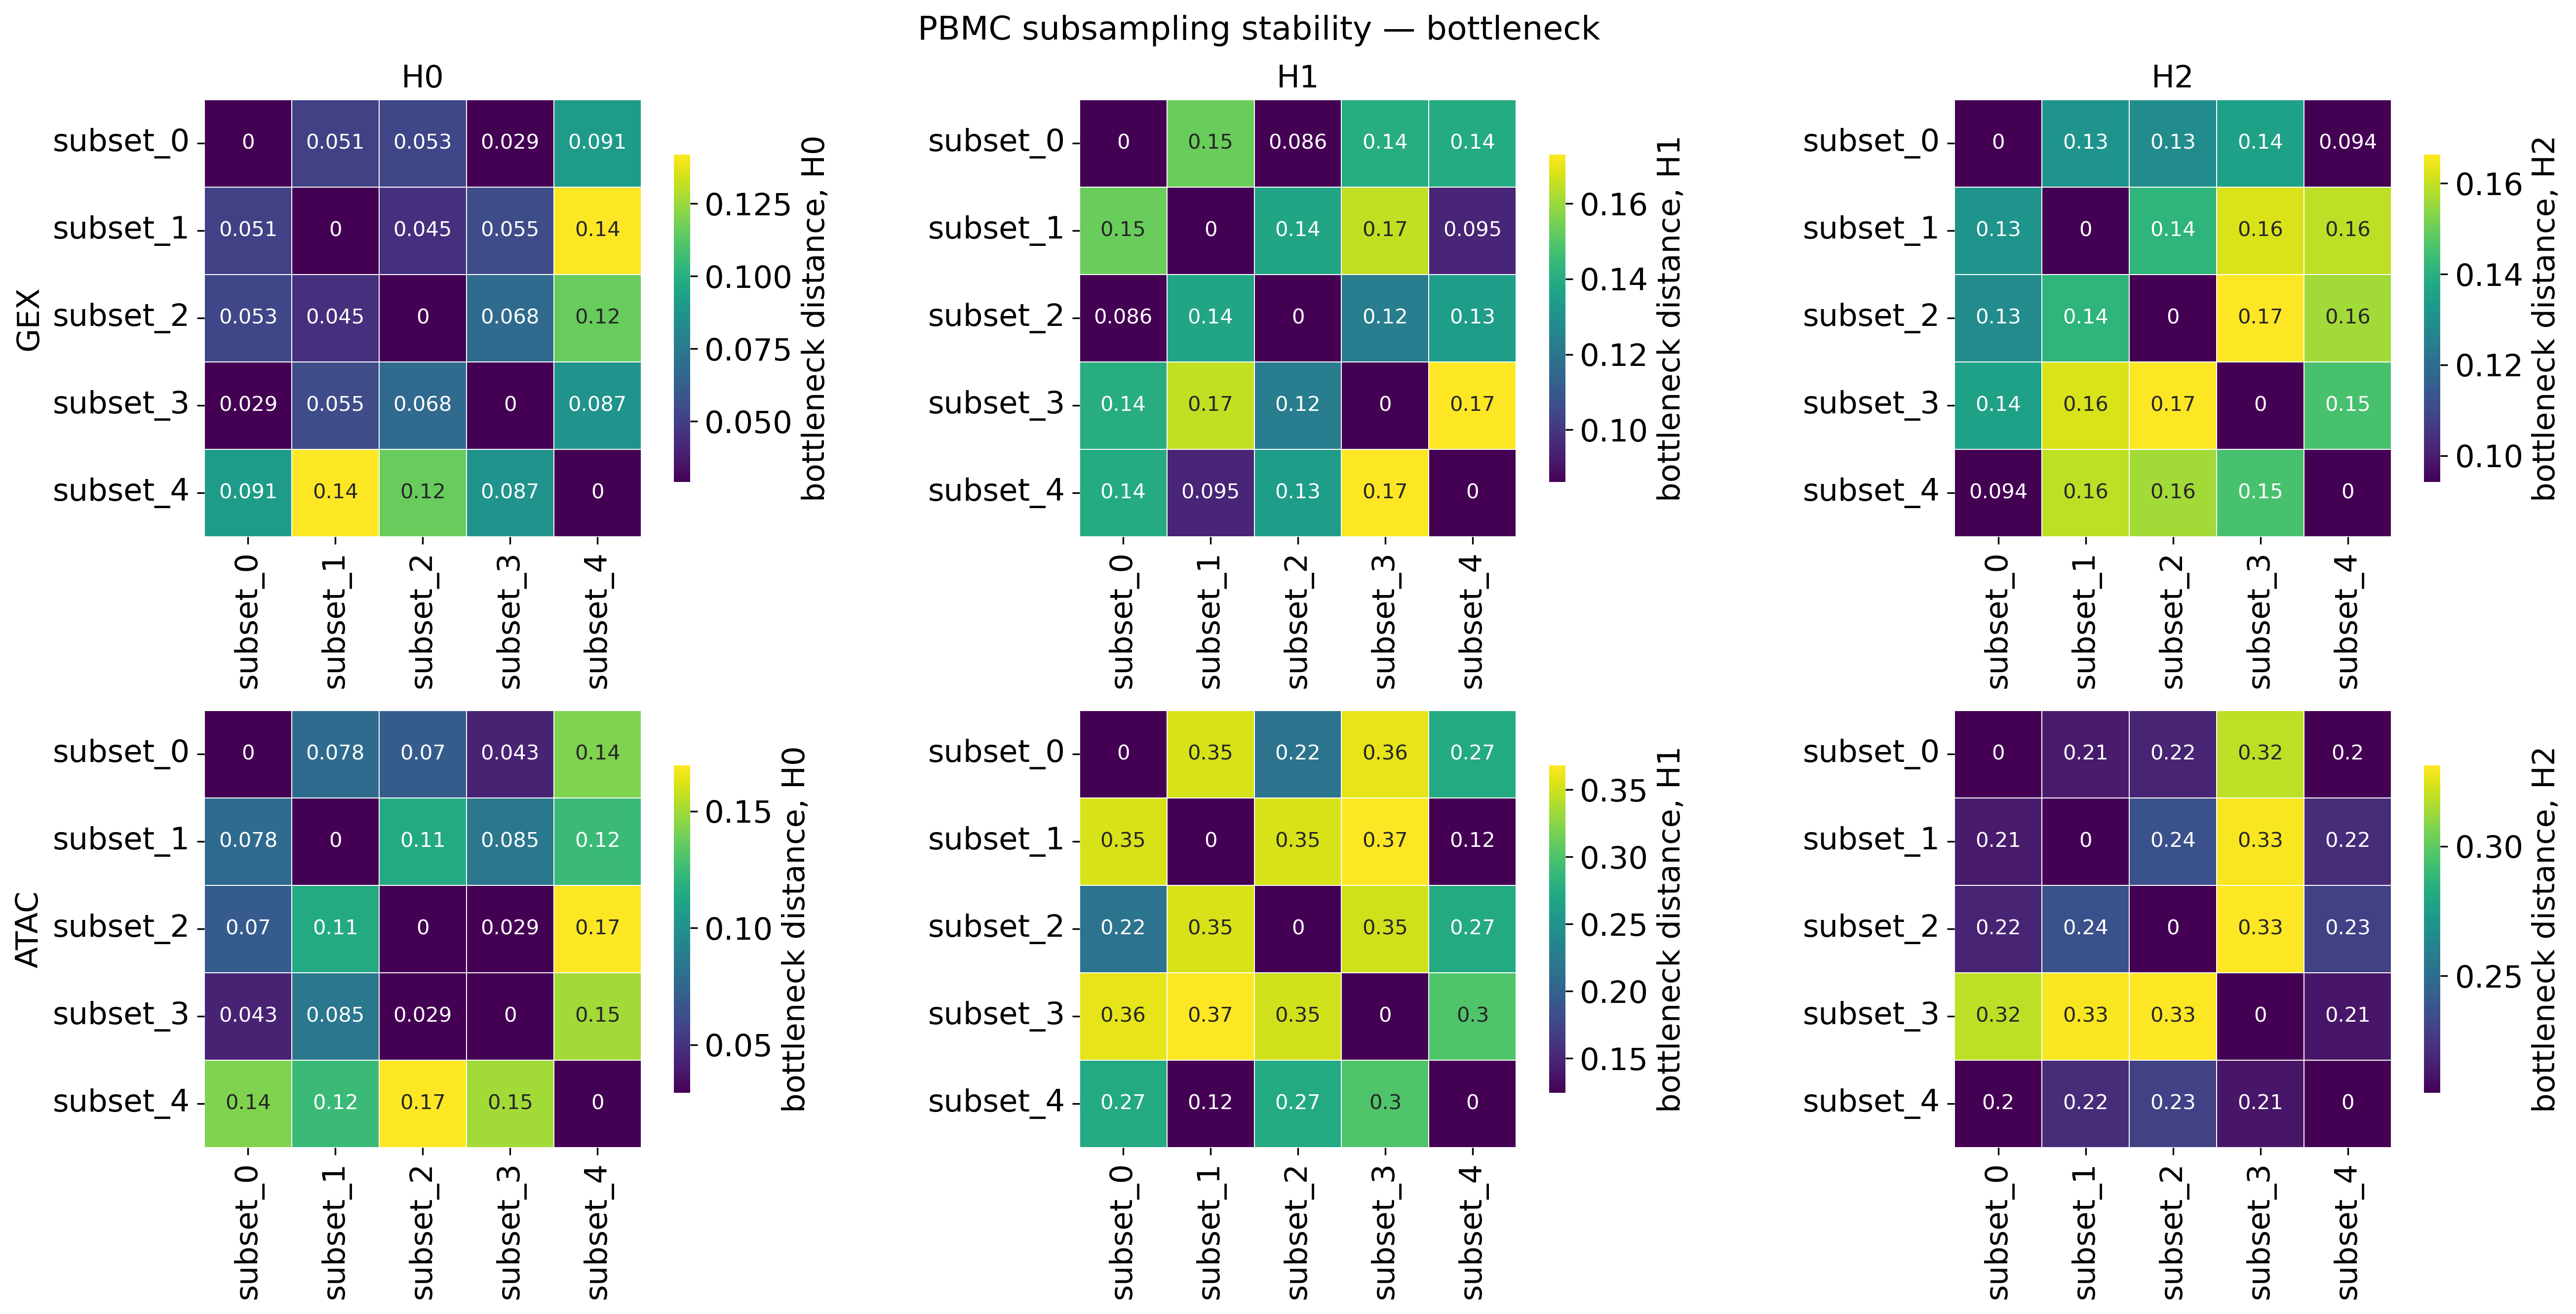

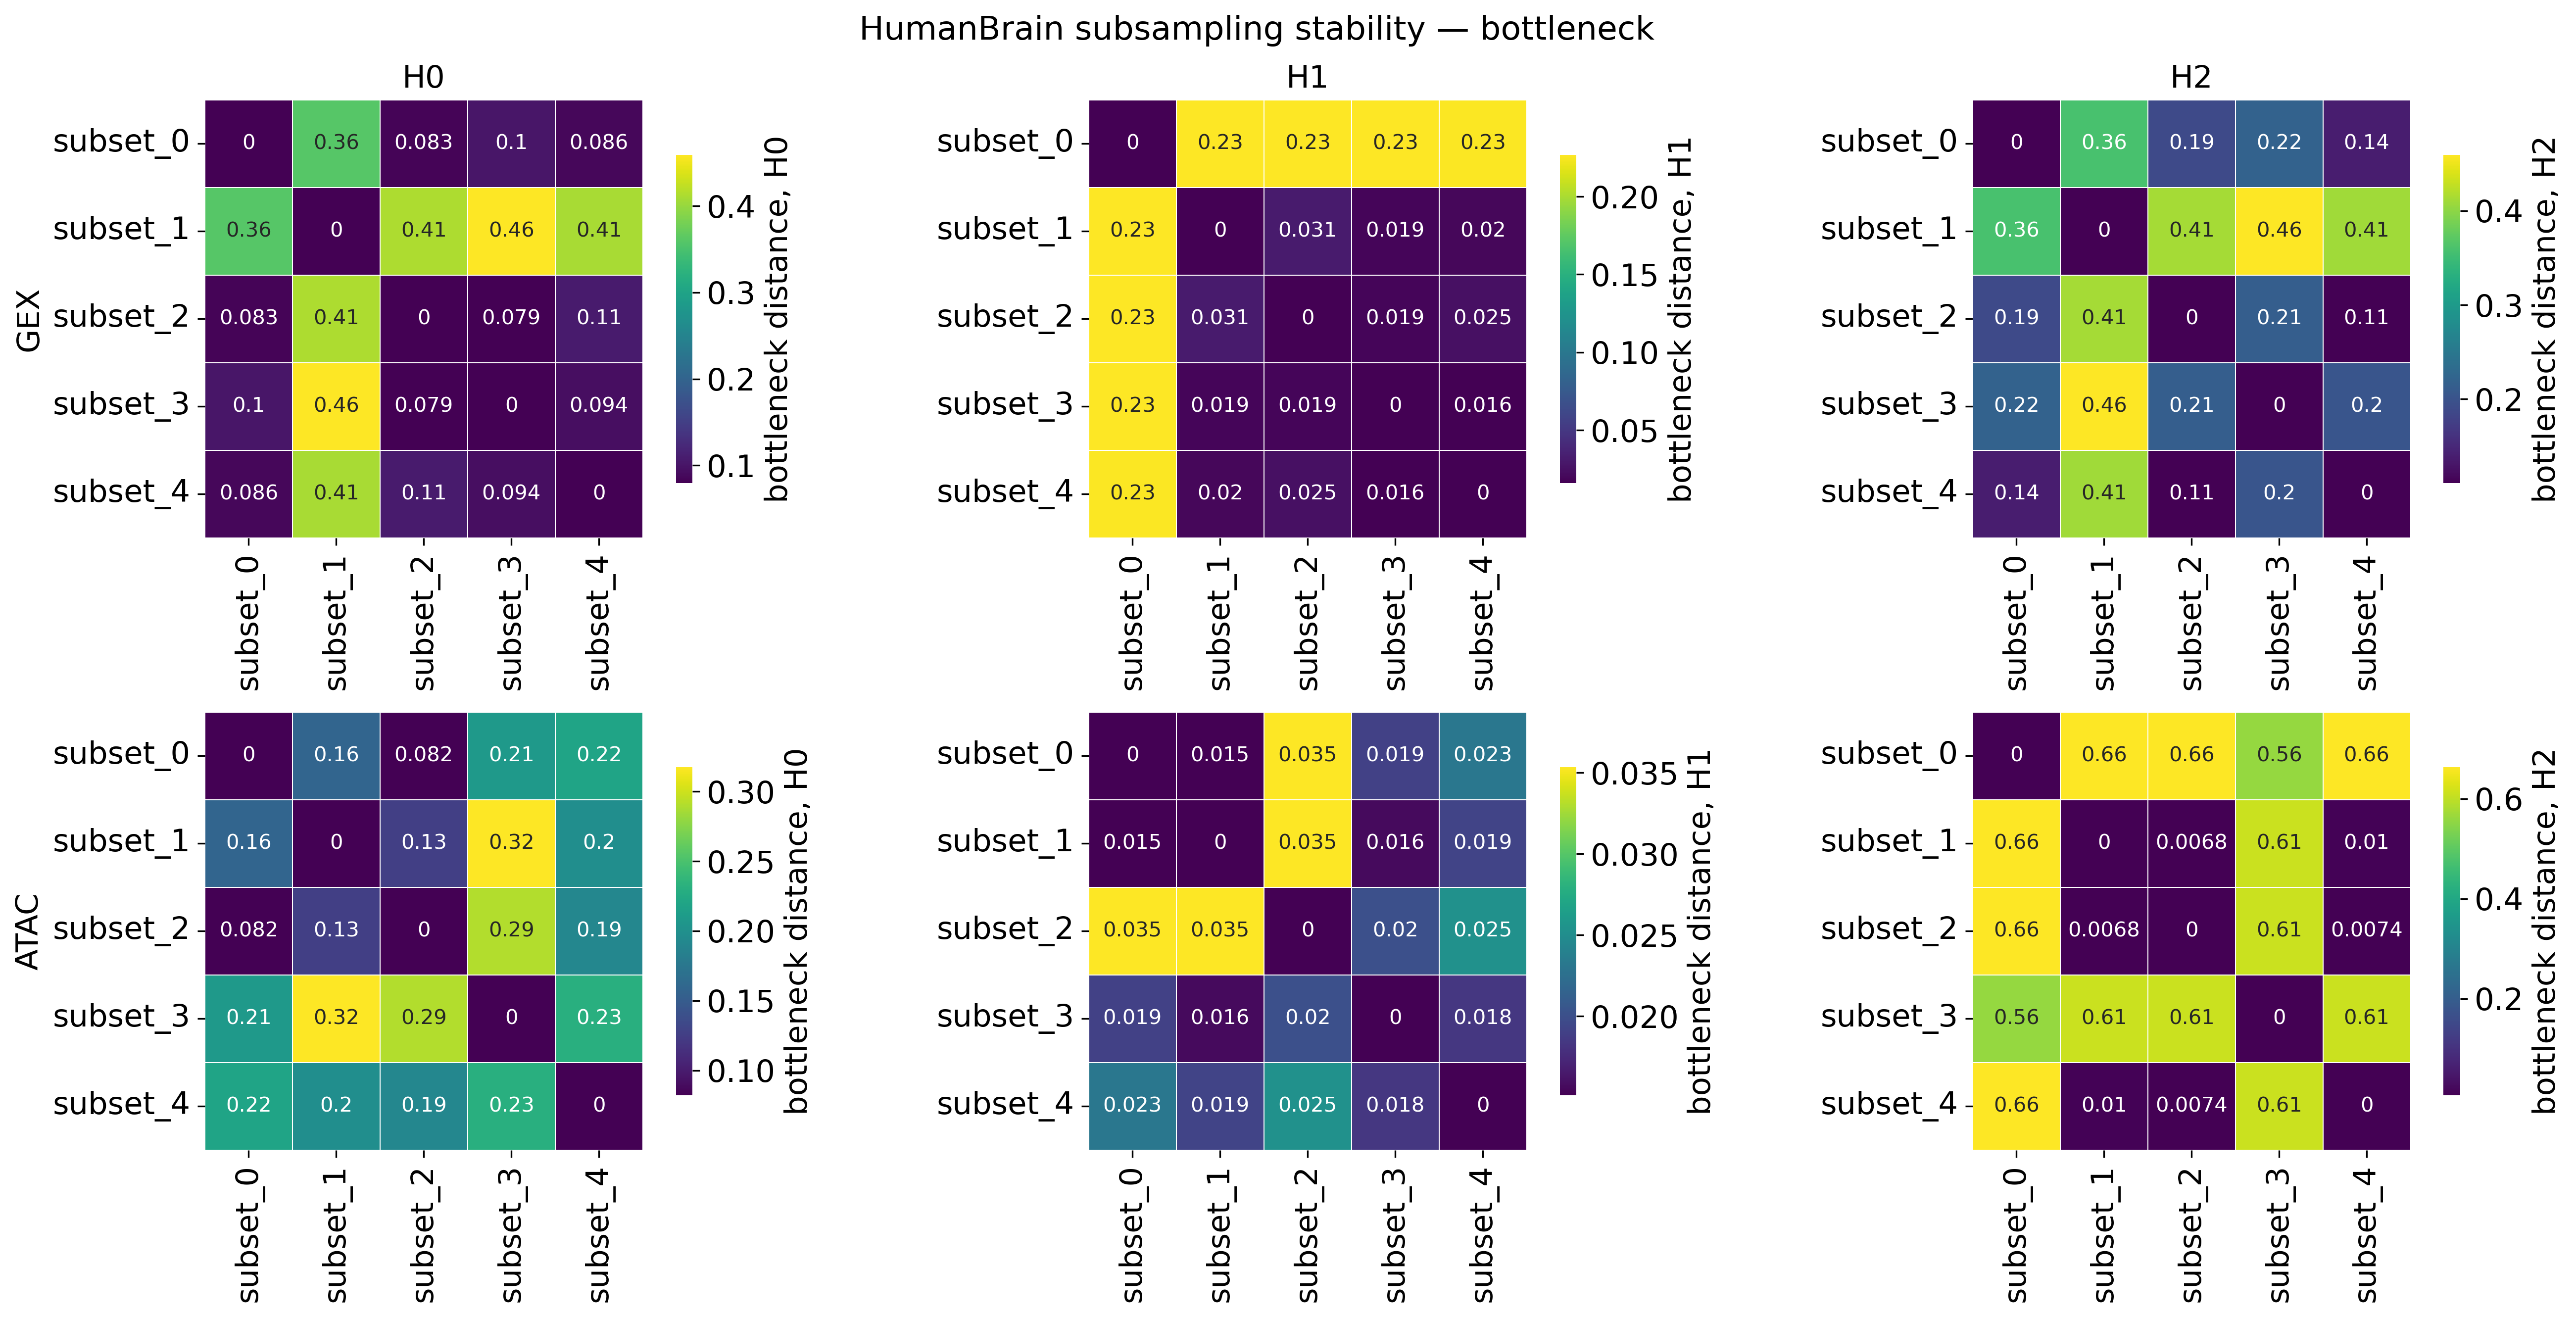

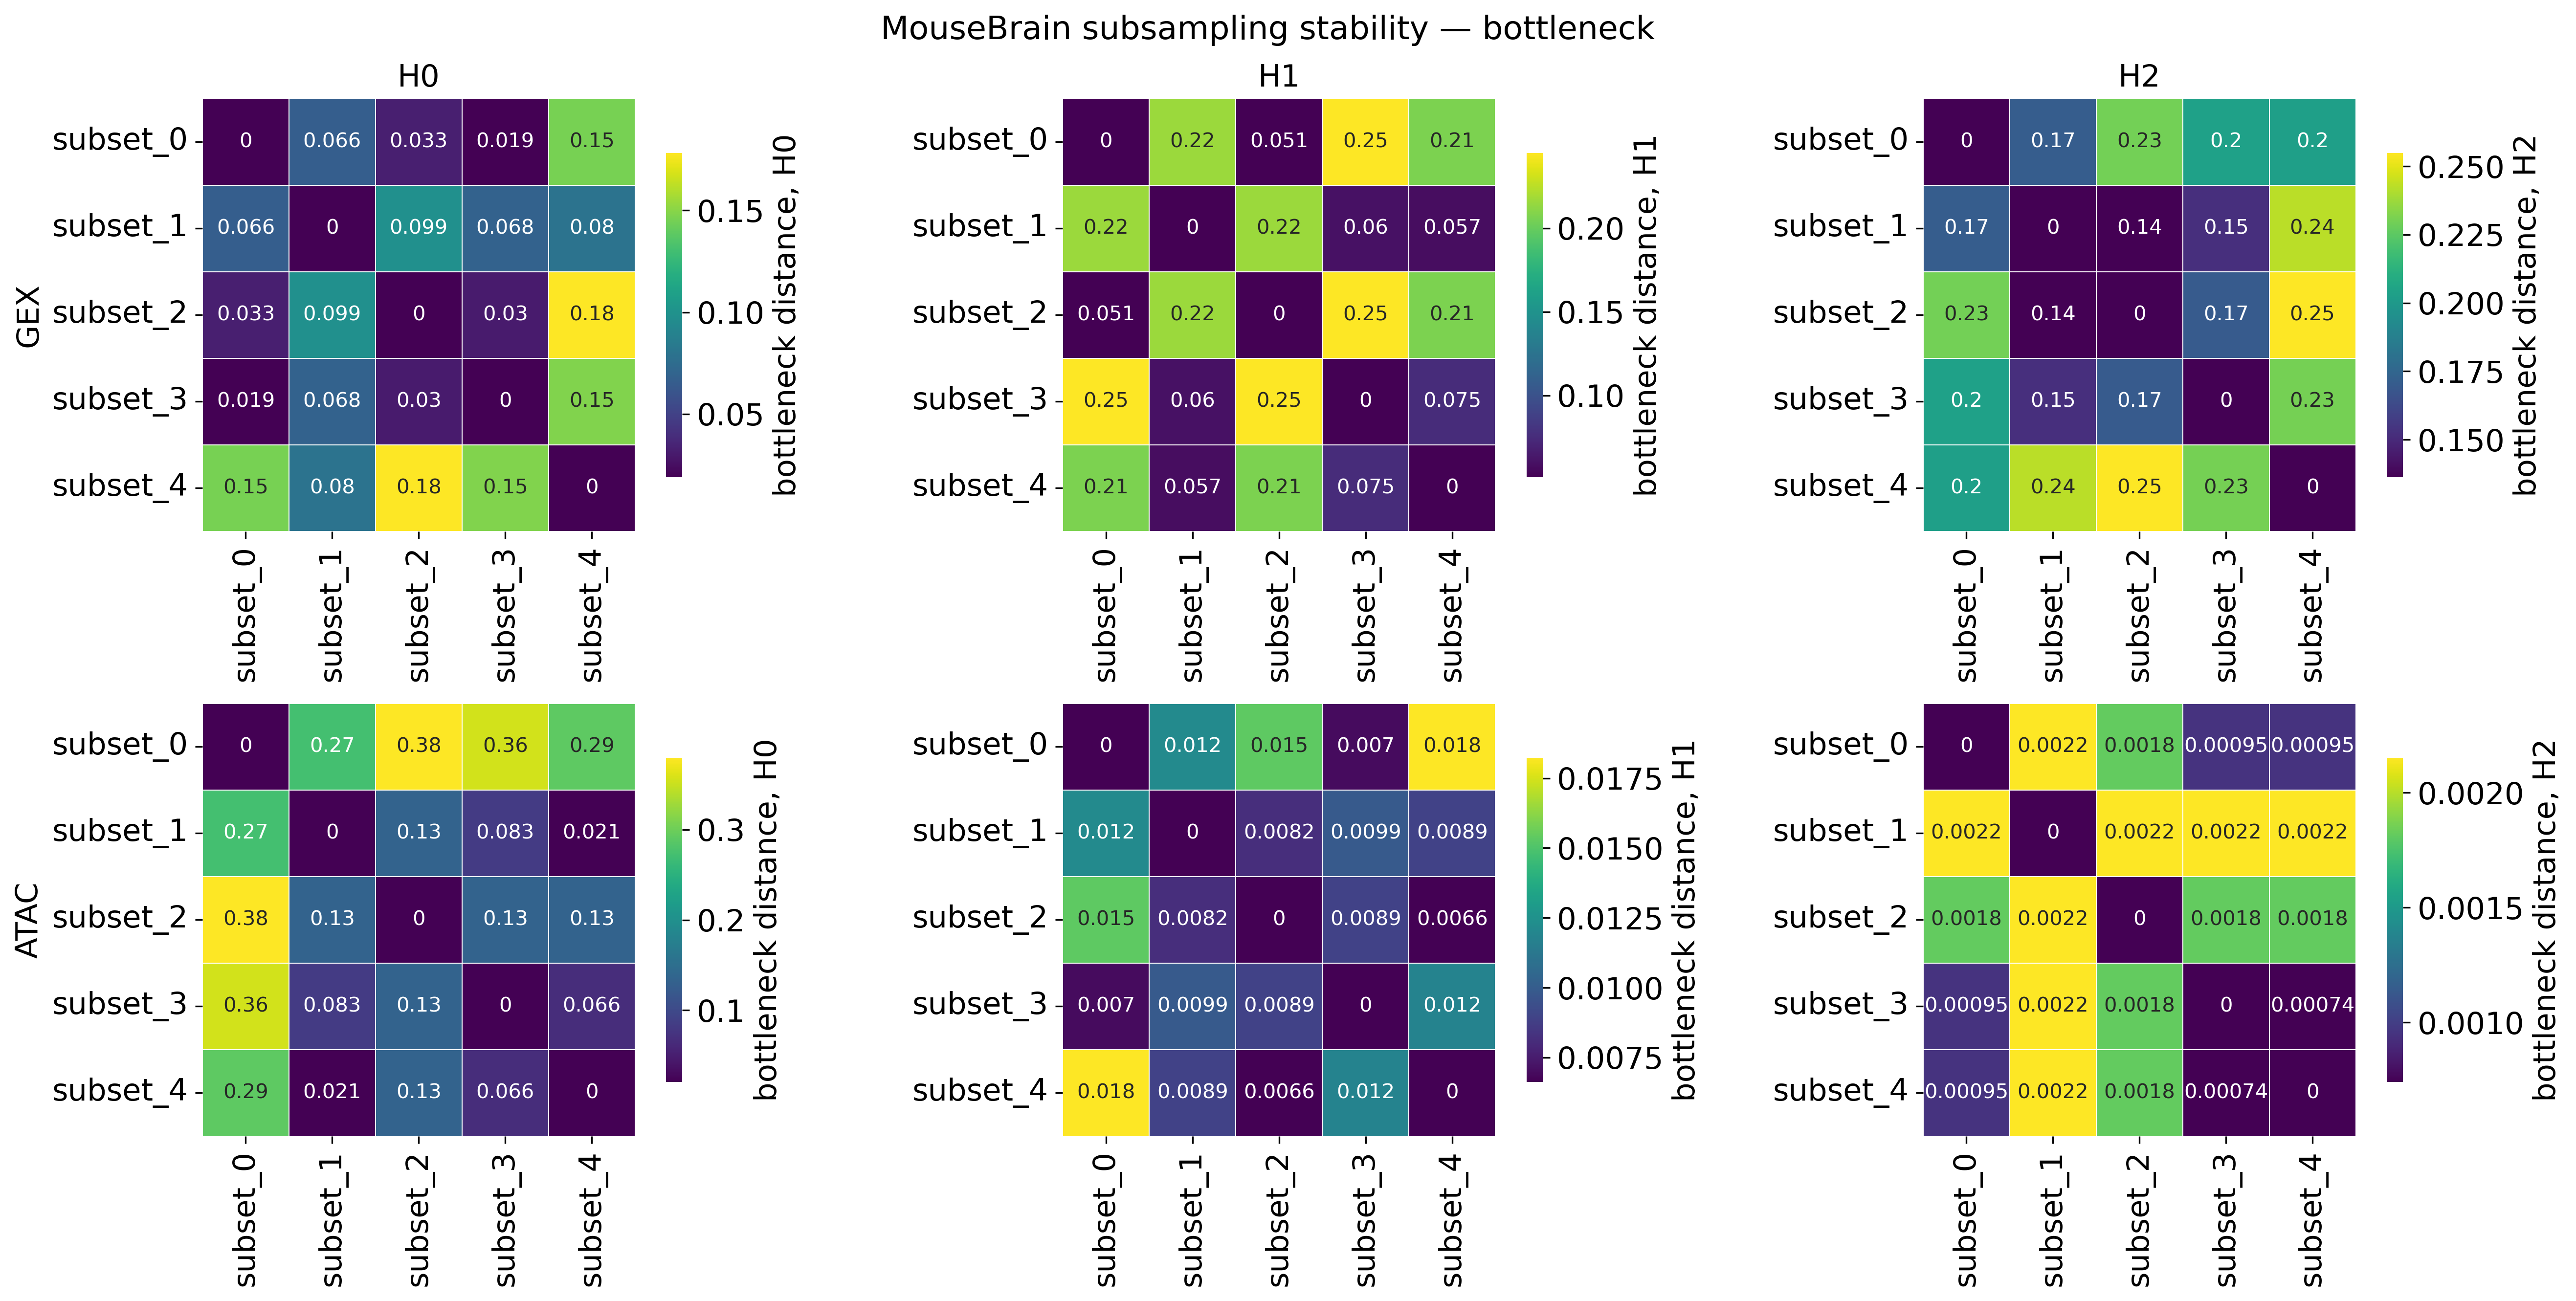

In [31]:
for dataset in datasets:
    for metric in metrics:
        fig, axes = plt.subplots(len(omics), len(dims), figsize=(18, 9), dpi=300, squeeze=False)

        for i, omic in enumerate(omics):
            for j, dim in enumerate(dims):
                ax = axes[i, j]
                sub = df.query(
                    "dataset == @dataset and omic == @omic and homology_dim == @dim and metric == @metric"
                )

                if sub.empty:
                    ax.axis("off")
                    ax.set_title(f"H{dim} — missing")
                    continue

                labels = sorted(set(sub.label_a) | set(sub.label_b), key=subset_value)
                mat = pd.DataFrame(0.0, index=labels, columns=labels)

                for r in sub.itertuples(index=False):
                    mat.loc[r.label_a, r.label_b] = r.distance
                    mat.loc[r.label_b, r.label_a] = r.distance

                vals = mat.to_numpy()
                off = vals[~np.eye(vals.shape[0], dtype=bool)]
                off = off[np.isfinite(off)]
                vmin, vmax = (off.min(), off.max()) if len(off) else (vals.min(), vals.max())

                sns.heatmap(
                    mat, ax=ax, cmap="viridis", vmin=vmin, vmax=vmax,
                    annot=True, fmt=".2g", square=True,
                    linewidths=0.4, linecolor="white",
                    cbar=True, cbar_kws={"label": f"{metric} distance, H{dim}", "shrink": 0.75}
                )

                ax.set_title(f"H{dim}" if i == 0 else "")
                ax.set_ylabel(("ATAC" if omic == "Peak" else omic) if j == 0 else "")
                ax.set_xlabel("")
                ax.tick_params(axis="x", rotation=90)
                ax.tick_params(axis="y", rotation=0)

        fig.suptitle(f"{dataset} subsampling stability — {metric}", fontsize=16)
        plt.tight_layout()
        plt.show()

bottleneck_distance


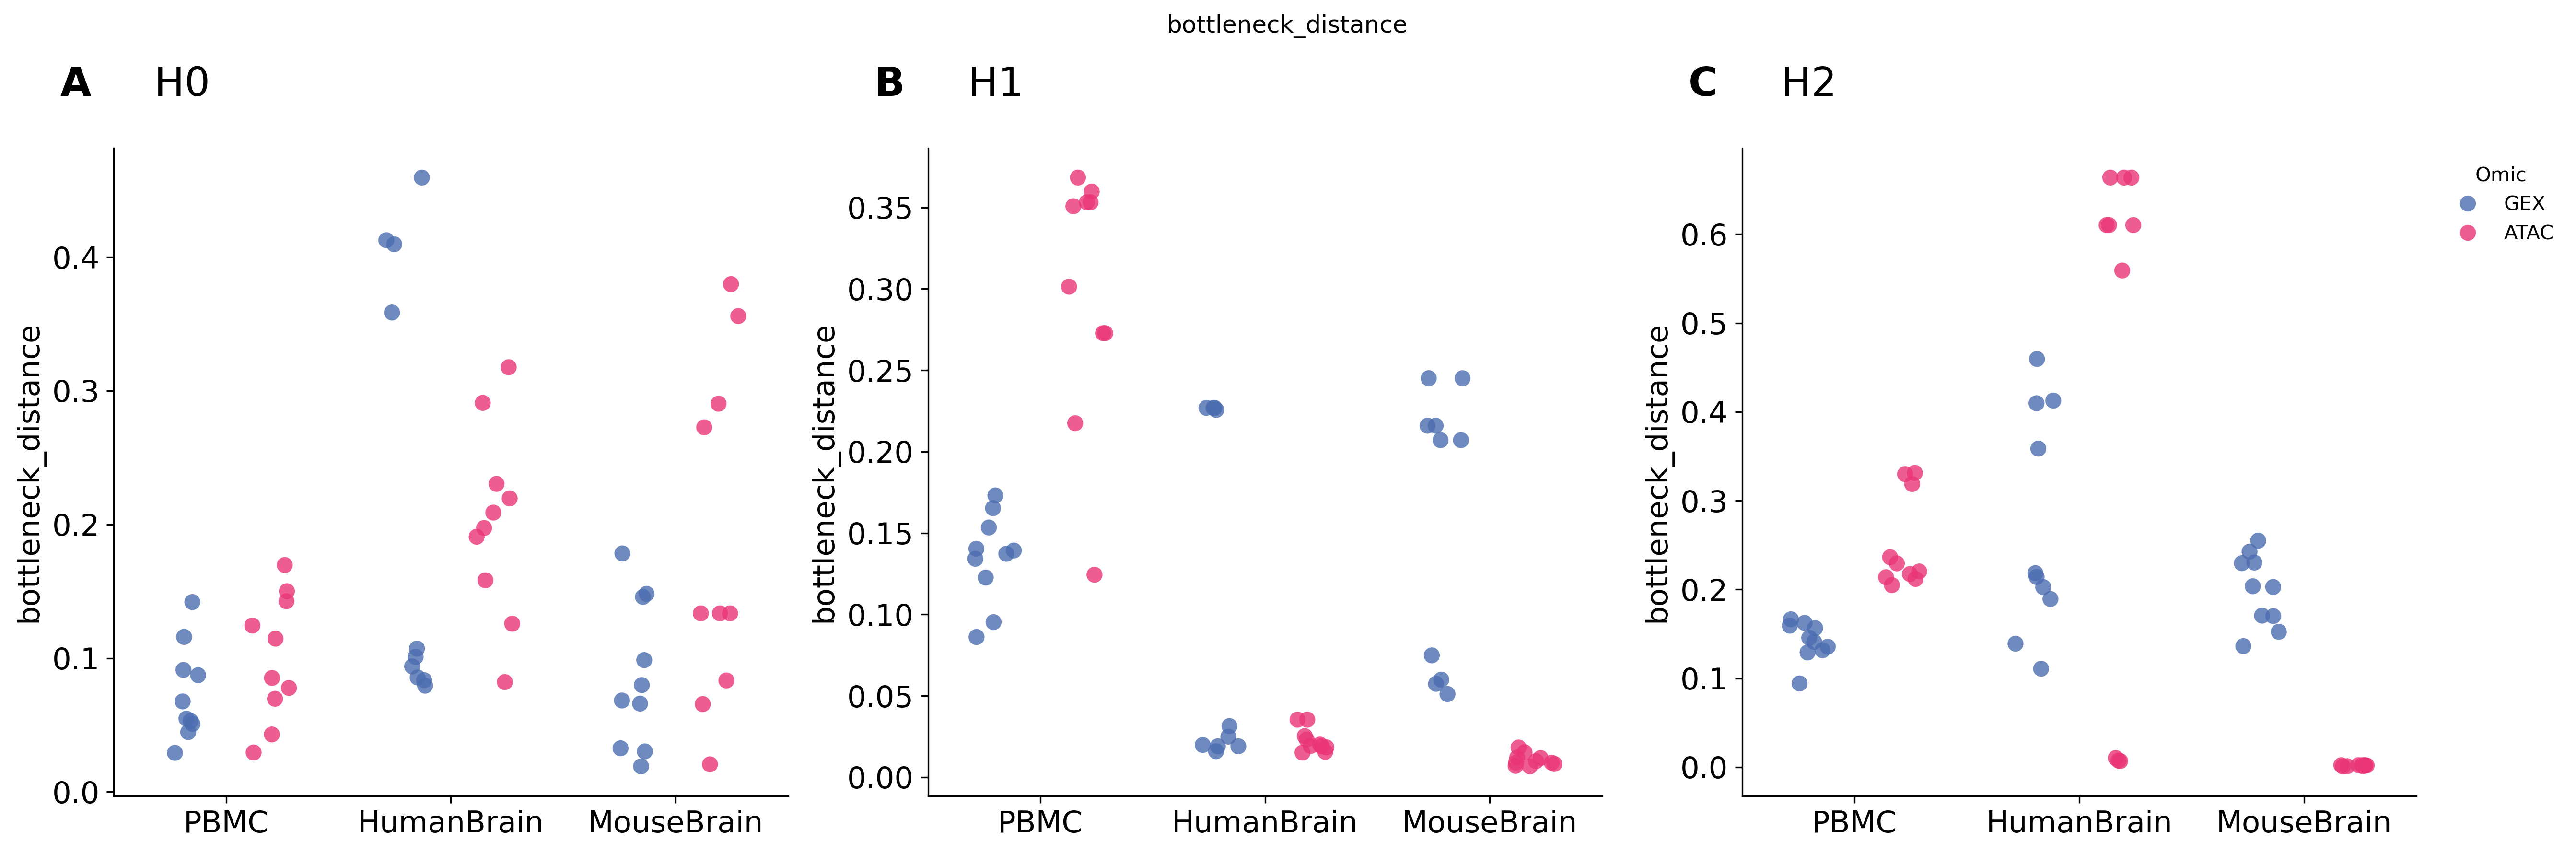

bottleneck_norm_by_diameter


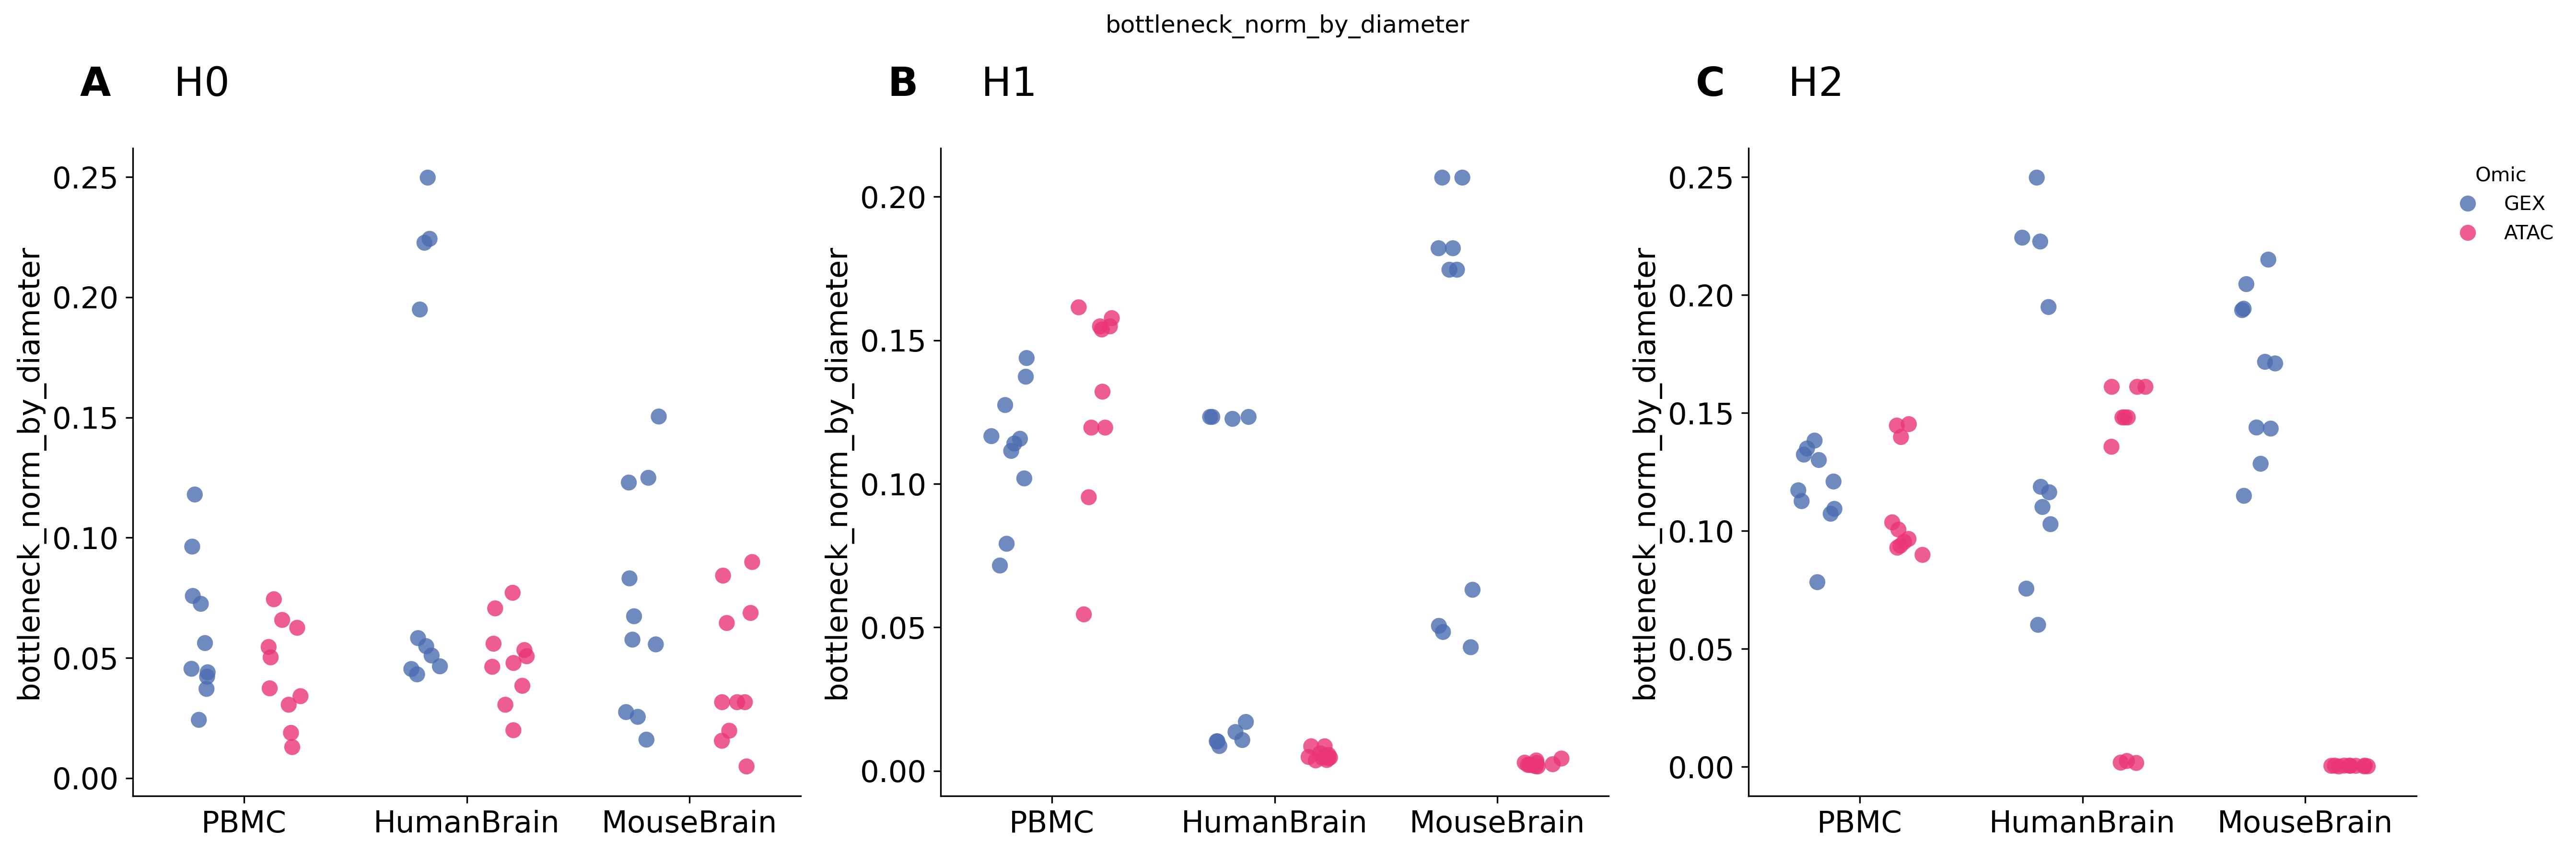

bottleneck_norm_by_filtration_range


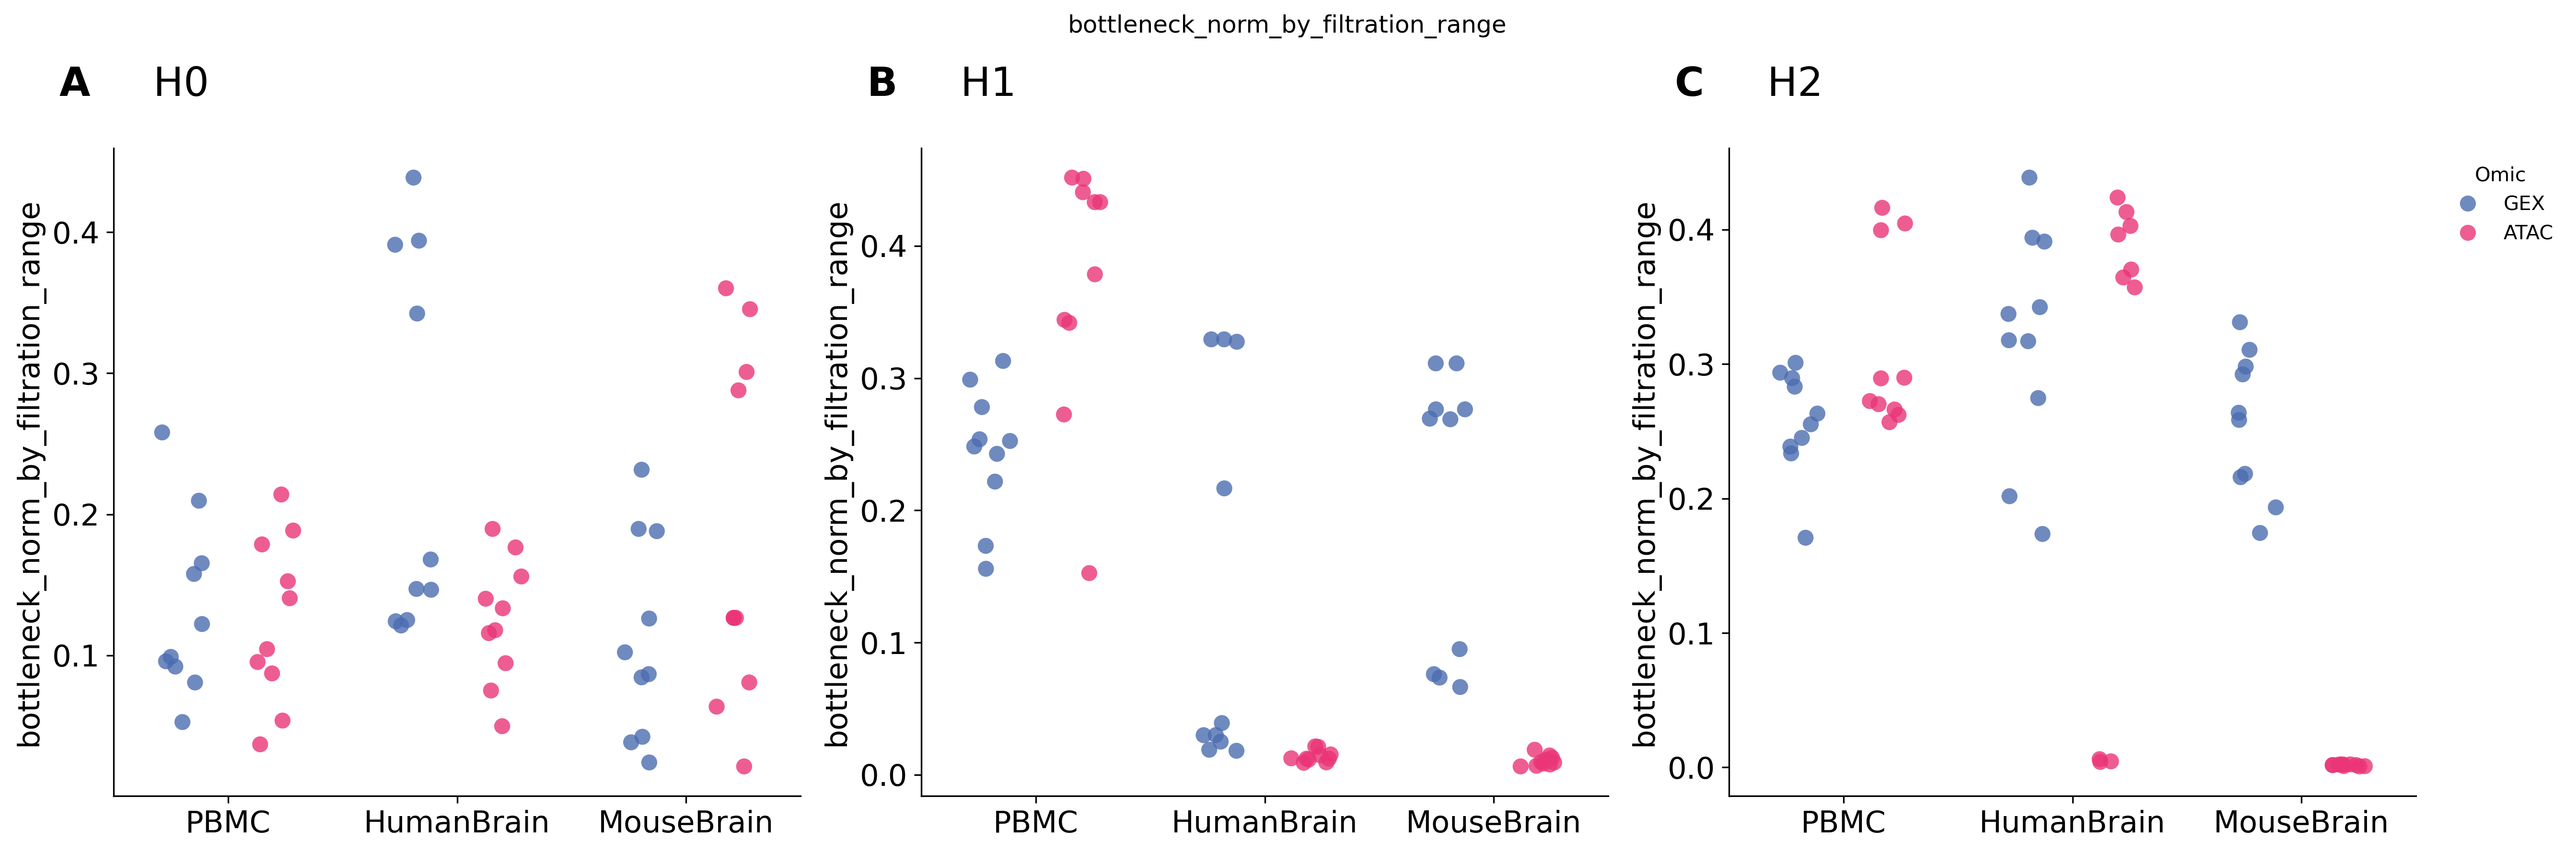

bottleneck_norm_by_longest_lifespan_dim


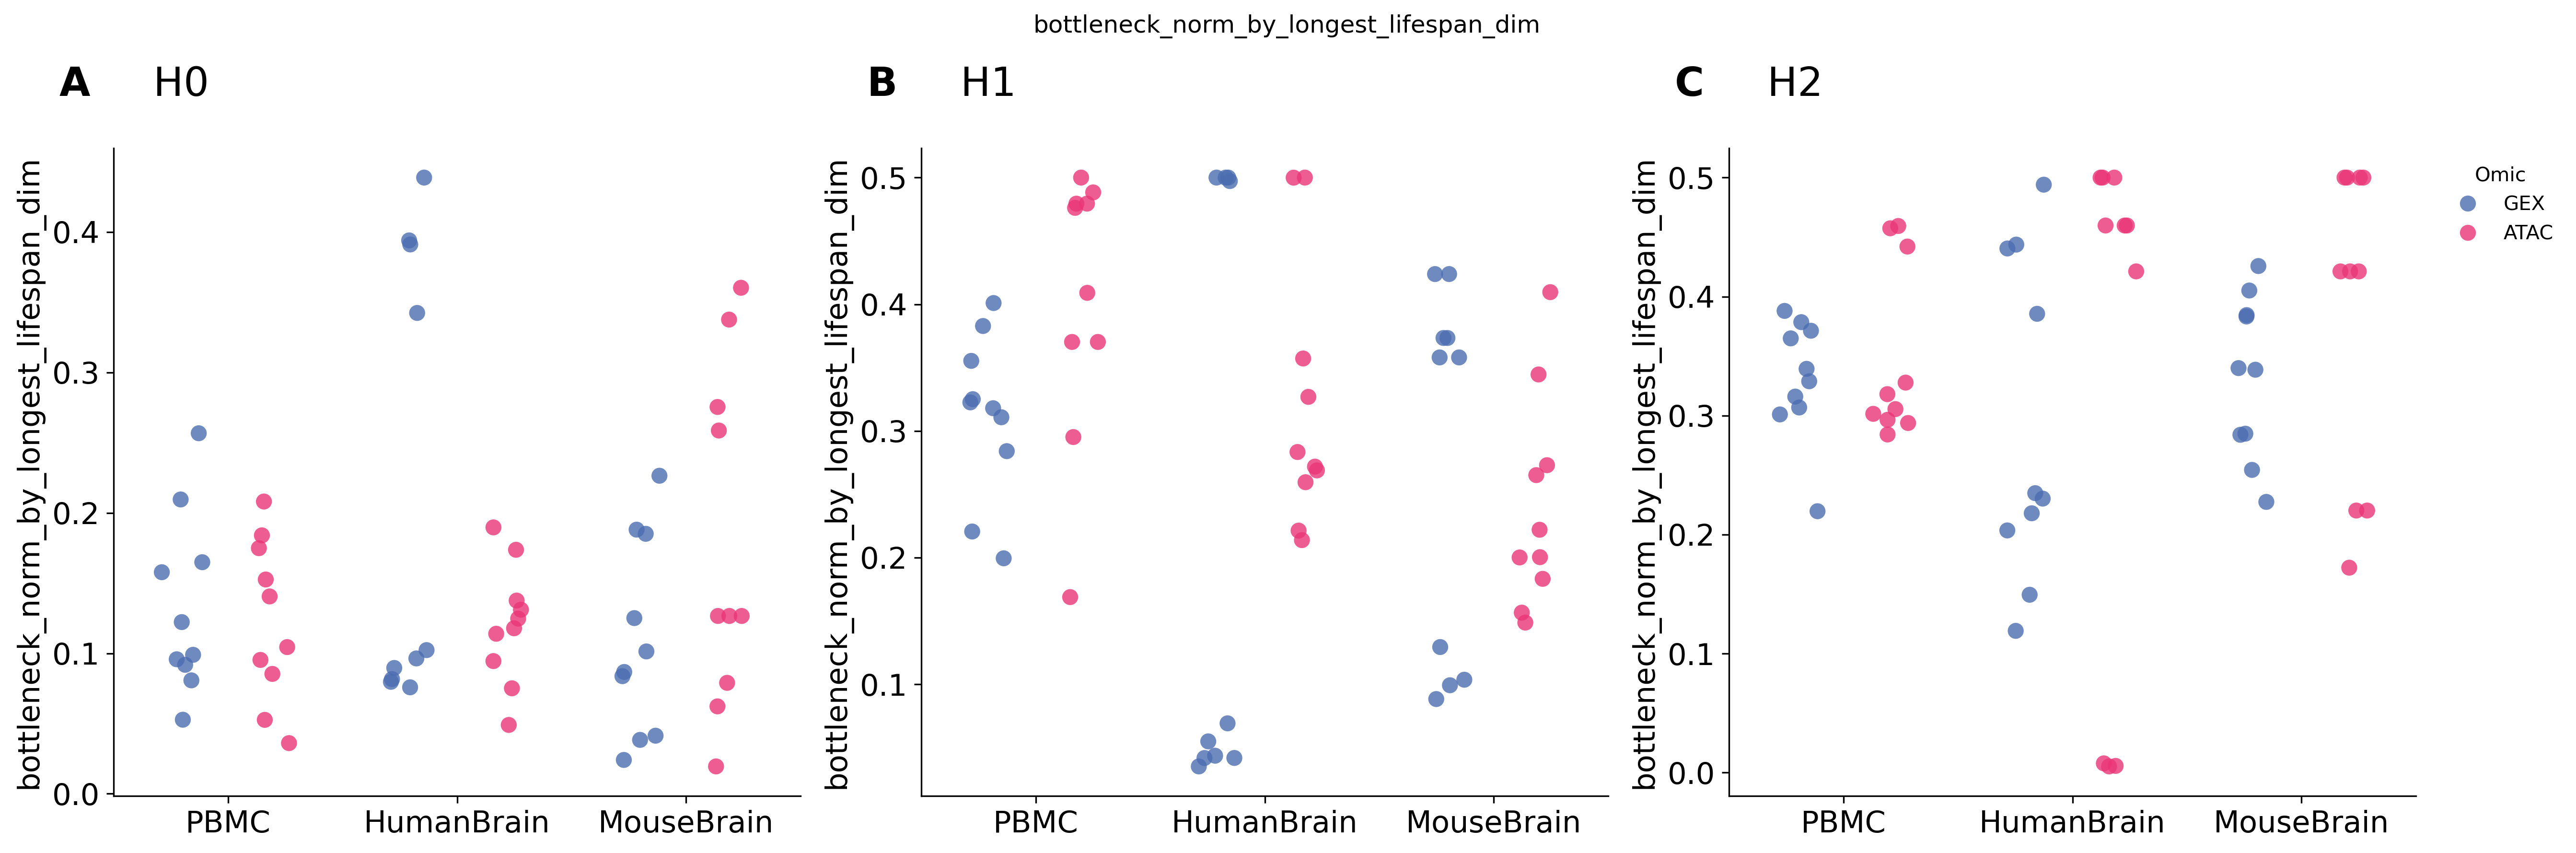

In [7]:
# -----------------------------
# user settings
# -----------------------------
datasets = ["PBMC", "HumanBrain", "MouseBrain"]
omics = ["GEX", "Peak"]
dims = [0, 1, 2]
metric = "bottleneck"   # or "wasserstein"

omic_colors = {
    "GEX": colors_to_use[19],
    "Peak": colors_to_use[16],
}
omic_labels = {
    "GEX": "GEX",
    "Peak": "ATAC",
}

plt.rcParams.update({
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.dpi": 300,
    "figure.figsize": [18, 6],
})

# -----------------------------
# prepare dataframe
# -----------------------------
plot_df = df[
    df["dataset"].isin(datasets)
    & df["omic"].isin(omics)
    & df["homology_dim"].isin(dims)
    & df["metric"].eq(metric)
].copy()

plot_df["omic_label"] = plot_df["omic"].map(omic_labels)

# -----------------------------
# plot
# -----------------------------
for distance in [col for col in df.columns if "bottleneck" in col]:
    print(distance)
    fig, axs = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    
    for i, dim in enumerate(dims):
        ax = axs[i]
        sub = plot_df[plot_df["homology_dim"] == dim].copy()
    
        sns.stripplot(
            data=sub,
            x="dataset",
            y=distance,
            hue="omic_label",
            order=datasets,
            hue_order=[omic_labels[o] for o in omics],
            palette={omic_labels[o]: omic_colors[o] for o in omics},
            dodge=True,
            jitter=0.18,
            size=8,
            alpha=0.8,
            ax=ax,
        )
    
        ax.set_title(rf"$\mathbf{{{string.ascii_uppercase[i]}}}$     H{dim}",
                     loc="left", size=20, pad=10, y=1.05, x=-0.08)
        ax.set_xlabel("")
        ax.set_ylabel(distance)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(False)
    
        if i != 2 and ax.get_legend() is not None:
            ax.get_legend().remove()
    
    # single legend
    handles, labels = axs[-1].get_legend_handles_labels()
    axs[-1].legend(handles, labels, title="Omic", frameon=False,
                   bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.suptitle(distance)
    fig.tight_layout()
    plt.show()